# Notebook B — Thí Nghiệm và Kết Quả Nghiên Cứu
## Credit Card Fraud Detection Using Machine Learning and Generalization Evaluation on Unseen Data

---

## 1. Giao Thức Nghiên Cứu và Ba Câu Hỏi Nghiên Cứu (Research Questions)

Notebook này tiếp nối Notebook A, tiêu thụ các tập dữ liệu đã phân chia chuẩn mực để thực hiện các thí nghiệm có kiểm soát nhằm trả lời ba câu hỏi nghiên cứu cốt lõi:

| # | Research Question |
|---|---|
| **RQ1** | **Which class imbalance handling technique is most effective for credit card fraud detection?** |
| **RQ2** | **Which machine learning model and classification threshold provide the best trade-off between fraud detection and false positive reduction?** |
| **RQ3** | **How well does the selected machine learning model, with its optimized classification threshold, generalize to previously unseen transaction data?** |

---

## 2. Quy Trình Thí Nghiệm (Experimental Workflow)

```
data/processed/ (X_train, y_train, X_validation, y_validation, X_test, y_test, manifest.json)
        │
        ├─► [Phần 3] Baseline (Logistic Regression thuần, threshold 0.5)
        │
        ├─► [Phần 4: RQ1] So sánh 4 kỹ thuật xử lý mất cân bằng lớp (LR cố định, val set, threshold 0.5)
        │                  Chọn kỹ thuật tối ưu theo Validation F2-score
        │
        ├─► [Phần 5: RQ2a] So sánh 6 mô hình học máy (áp dụng kỹ thuật RQ1, val set, threshold mặc định)
        │                   Chọn mô hình tối ưu theo Validation Average Precision (AP)
        │
        ├─► [Phần 6: RQ2b] Tối ưu hóa ngưỡng phân loại (chỉ trên validation set) theo Policy A (max F2)
        │
        ├─► [Phần 7] Đóng băng cấu hình cuối cùng (Frozen Configuration) & lưu JSON
        │
        ├─► [Phần 8: RQ3] Đánh giá trên tập test chưa thấy (chỉ một lần duy nhất, không điều chỉnh)
        │
        ├─► [Phần 9] Phân tích tổng quát hóa (Validation vs Test, Bootstrap CI)
        ├─► [Phần 10] Phân tích lỗi (Error Analysis: FP & FN)
        └─► [Phần 11] Kết luận tổng hợp, xuất 4 bảng và 5 hình bài báo
```

### Nguyên Tắc Bất Di Bất Dịch Về Dữ Liệu:
1. **Tập Test (15%) hoàn toàn không được đụng chạm** cho tới Phần 8. Không dùng test set để chọn mô hình, chọn ngưỡng, chọn đặc trưng hay tune tham số.
2. **Không rò rỉ dữ liệu (No Data Leakage):** Scaler chỉ fit trên train; các kỹ thuật cân bằng dữ liệu (SMOTE, Under-Sampling) chỉ áp dụng trên train. Validation và test giữ nguyên phân phối thực tế.
3. **Tái lập hoàn toàn (Reproducibility):** Cố định RANDOM_SEED = 42 xuyên suốt mọi bước.
4. **Phạm vi của "unseen data" (RQ3):** Notebook A chia dữ liệu ngẫu nhiên có phân tầng 70/15/15, không chia theo thời gian. "Unseen" ở đây nghĩa là tập Test chưa được dùng để huấn luyện, chọn mô hình hay chọn ngưỡng. Kết quả chỉ nói về tập giữ lại theo cách chia này, không chứng minh mô hình dự đoán tốt giao dịch trong tương lai hay ở ngân hàng khác (chưa đánh giá theo thời gian).

---
## Phần 1 — Nạp và Xác Minh Dữ Liệu Đã Chuẩn Bị

**Mục tiêu:** Nạp manifest và 6 tệp dữ liệu đã phân chia từ Notebook A (`data/processed/`).
Tiến hành kiểm tra nghiêm ngặt: số cột, kiểu dữ liệu, tính toàn vẹn của nhãn, kích thước và kiểm tra không chồng chéo chỉ số.

In [1]:
# 1.1 Kiem tra phien ban Python va thu vien
import sys
print(f'Python version: {sys.version}')

REQUIRED_PACKAGES = {
    'pandas': 'pandas',
    'numpy': 'numpy',
    'scipy': 'scipy',
    'sklearn': 'scikit-learn',
    'imblearn': 'imbalanced-learn',
    'matplotlib': 'matplotlib',
    'seaborn': 'seaborn',
    'joblib': 'joblib',
}

missing_pkgs = []
for mod, pip_name in REQUIRED_PACKAGES.items():
    try:
        __import__(mod)
        print(f'  ✔ {pip_name}')
    except ImportError:
        print(f'  ✘ {pip_name} (chua cai dat)')
        missing_pkgs.append(pip_name)

if missing_pkgs:
    raise ImportError(f'Thieu cac thu vien: {missing_pkgs}. Vui long cai dat truoc khi tiep tuc.')
print('✔ Moi truong hop le, tat ca thu vien da san sang.')

# Thu vien tuy chon: XGBoost (neu thieu, RQ2 bo qua XGBoost, chay cac mo hinh con lai va ghi lai ly do)
try:
    import xgboost
    XGBOOST_AVAILABLE = True
    print('  ✔ xgboost (tuy chon)')
except ImportError:
    XGBOOST_AVAILABLE = False
    print('  ! xgboost (tuy chon) chua cai dat: pip install xgboost. RQ2 se bo qua XGBoost va chay cac mo hinh con lai (toi da 6 mo hinh).')

# Ghi lai phien ban thu vien de tai lap
import importlib
LIB_VERSIONS = {'python': sys.version.split()[0]}
for _mod in list(REQUIRED_PACKAGES) + (['xgboost'] if XGBOOST_AVAILABLE else []):
    LIB_VERSIONS[_mod] = getattr(importlib.import_module(_mod), '__version__', 'unknown')
print('Phien ban thu vien:', LIB_VERSIONS)


Python version: 3.13.16 (tags/v3.13.16:cbc944f, Sep 30 2026, 19:17:50) [MSC v.1944 64 bit (AMD64)]
  ✔ pandas
  ✔ numpy
  ✔ scipy
  ✔ scikit-learn
  ✔ imbalanced-learn
  ✔ matplotlib
  ✔ seaborn
  ✔ joblib
✔ Moi truong hop le, tat ca thu vien da san sang.
  ✔ xgboost (tuy chon)
Phien ban thu vien: {'python': '3.13.16', 'pandas': '2.3.3', 'numpy': '2.5.3', 'scipy': '1.18.1', 'sklearn': '1.9.1', 'imblearn': '0.14.2', 'matplotlib': '3.11.2', 'seaborn': '0.13.2', 'joblib': '1.6.0', 'xgboost': '3.4.1'}


In [2]:
# 1.2 Import thu vien va thiet lap duong dan
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# Scikit-Learn
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, fbeta_score, average_precision_score,
    confusion_matrix, precision_recall_curve, auc
)

# Imbalanced-Learn
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.ensemble import BalancedRandomForestClassifier

if XGBOOST_AVAILABLE:
    from xgboost import XGBClassifier

warnings.filterwarnings('ignore')

# Thiet lap do hoa tieu chuan cho bai bao
matplotlib.rcParams.update({
    'figure.dpi': 120,
    'font.size': 10,
    'font.family': 'sans-serif',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.labelsize': 10,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'legend.fontsize': 9,
})

# Thiet lap duong dan du an bang pathlib.Path
PROJECT_ROOT = Path(r"C:\Users\lmlmdf404\Desktop\credit_card_fraud_project")
if not PROJECT_ROOT.exists():
    for parent in [Path.cwd()] + list(Path.cwd().parents):
        if (parent / 'data').is_dir() and (parent / 'notebooks').is_dir():
            PROJECT_ROOT = parent
            break

print(f'Thu muc goc du an: {PROJECT_ROOT}')

DATA_PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
RESULTS_DIR        = PROJECT_ROOT / 'results'
TABLES_DIR         = RESULTS_DIR / 'tables'
TABLES_PAPER_DIR   = RESULTS_DIR / 'tables' / 'paper'
FIGURES_EXP_DIR    = RESULTS_DIR / 'figures' / 'exploratory'
FIGURES_PAPER_DIR  = RESULTS_DIR / 'figures' / 'paper'
METRICS_DIR        = RESULTS_DIR / 'metrics'

for d in [TABLES_DIR, TABLES_PAPER_DIR, FIGURES_EXP_DIR, FIGURES_PAPER_DIR, METRICS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

RANDOM_SEED = 42


Thu muc goc du an: C:\Users\lmlmdf404\Desktop\credit_card_fraud_project


In [3]:
# 1.3 Nap manifest va kiem tra tinh nguyen ven
manifest_file = DATA_PROCESSED_DIR / 'manifest.json'
if not manifest_file.exists():
    raise FileNotFoundError(
        f'Khong tim thay {manifest_file}.\n'
        'Ban phai chay Notebook_A_Data_Preparation.ipynb truoc de tao du lieu da chuan bi.'
    )

with open(manifest_file, 'r', encoding='utf-8') as f:
    manifest = json.load(f)

print('✔ Manifest da duoc nap thanh cong:')
print(f"  - Ngay tao:            {manifest.get('created_at')}")
print(f"  - Random Seed:         {manifest.get('random_seed')}")
print(f"  - Cot muc tieu:        {manifest.get('target_column')}")
print(f"  - So luong dac trung:  {manifest.get('n_features')}")
print(f"  - Ty le phan chia:     {manifest.get('split_proportions')}")

✔ Manifest da duoc nap thanh cong:
  - Ngay tao:            2026-10-29T09:17:36.254199+00:00
  - Random Seed:         42
  - Cot muc tieu:        Class
  - So luong dac trung:  30
  - Ty le phan chia:     {'train': 0.7, 'validation': 0.15, 'test': 0.15}


In [4]:
# 1.4 Doc 6 tap du lieu da phan chia
required_csvs = [
    'X_train.csv', 'y_train.csv',
    'X_validation.csv', 'y_validation.csv',
    'X_test.csv', 'y_test.csv'
]

for f in required_csvs:
    if not (DATA_PROCESSED_DIR / f).exists():
        raise FileNotFoundError(f'Thieu file: {DATA_PROCESSED_DIR / f}. Vui long chay Notebook A.')

X_train = pd.read_csv(DATA_PROCESSED_DIR / 'X_train.csv', index_col=0)
y_train = pd.read_csv(DATA_PROCESSED_DIR / 'y_train.csv', index_col=0).squeeze('columns')
X_val   = pd.read_csv(DATA_PROCESSED_DIR / 'X_validation.csv', index_col=0)
y_val   = pd.read_csv(DATA_PROCESSED_DIR / 'y_validation.csv', index_col=0).squeeze('columns')
X_test  = pd.read_csv(DATA_PROCESSED_DIR / 'X_test.csv', index_col=0)
y_test  = pd.read_csv(DATA_PROCESSED_DIR / 'y_test.csv', index_col=0).squeeze('columns')

print('✔ Da doc thanh cong 6 tap du lieu.')

# 1.5 Kiem tra nghiem ngat tinh nhat quan voi Manifest
assert list(X_train.columns) == list(X_val.columns) == list(X_test.columns), 'Cac cot dac trung khong nhat quan!'
assert len(X_train.columns) == manifest['n_features'], 'So luong cot khac manifest!'

# Kiem tra so dong voi manifest
assert len(X_train) == manifest['class_counts']['train']['rows'], 'So dong train khong khop manifest!'
assert len(X_val)   == manifest['class_counts']['validation']['rows'], 'So dong val khong khop manifest!'
assert len(X_test)  == manifest['class_counts']['test']['rows'], 'So dong test khong khop manifest!'

# Kiem tra so fraud trong tung tap
assert (y_train == 1).sum() == manifest['class_counts']['train']['fraud'], 'So fraud train khong khop!'
assert (y_val == 1).sum()   == manifest['class_counts']['validation']['fraud'], 'So fraud val khong khop!'
assert (y_test == 1).sum()  == manifest['class_counts']['test']['fraud'], 'So fraud test khong khop!'

# Kiem tra khong chong cheo index
idx_train, idx_val, idx_test = set(X_train.index), set(X_val.index), set(X_test.index)
assert len(idx_train & idx_val) == 0, 'Loi: Train va Validation bi trung lap index!'
assert len(idx_train & idx_test) == 0, 'Loi: Train va Test bi trung lap index!'
assert len(idx_val & idx_test) == 0, 'Loi: Validation va Test bi trung lap index!'

print('✔ Kiem tra hoan tat: Du lieu hoan toan nhat quan, khong co su ro ri index hay sai lech kich thuoc.')
summary_splits = pd.DataFrame({
    'Split': ['Train', 'Validation', 'Test'],
    'Total Rows': [len(X_train), len(X_val), len(X_test)],
    'Legitimate (0)': [(y_train == 0).sum(), (y_val == 0).sum(), (y_test == 0).sum()],
    'Fraud (1)': [(y_train == 1).sum(), (y_val == 1).sum(), (y_test == 1).sum()],
    'Fraud %': [(y_train == 1).mean()*100, (y_val == 1).mean()*100, (y_test == 1).mean()*100]
})
summary_splits['Fraud %'] = summary_splits['Fraud %'].map(lambda x: f'{x:.4f}%')
print(summary_splits.to_string(index=False))

✔ Da doc thanh cong 6 tap du lieu.
✔ Kiem tra hoan tat: Du lieu hoan toan nhat quan, khong co su ro ri index hay sai lech kich thuoc.
     Split  Total Rows  Legitimate (0)  Fraud (1) Fraud %
     Train      198608          198277        331 0.1667%
Validation       42559           42488         71 0.1668%
      Test       42559           42488         71 0.1668%


---
## Phần 2 — Hệ Thống Độ Đo Đánh Giá (Evaluation Metrics)

### 2.1 Tại Sao Accuracy Lại Gây Hiểu Nhầm Nghiêm Trọng?
Trong tập dữ liệu giao dịch thẻ tín dụng, lớp gian lận chỉ chiếm xấp xỉ **0.17%**.
Nếu một mô hình tầm thường ('naive classifier') luôn dự đoán nhãn 0 (hợp lệ) cho tất cả các giao dịch, nó sẽ đạt **Accuracy = 99.83%**.
Tuy nhiên, mô hình này hoàn toàn vô dụng vì bỏ lọt 100% các vụ lừa đảo (Recall = 0.0), gây thiệt hại tài chính khổng lồ.

### 2.2 Phân Biệt Các Nhóm Độ Đo
Ta phân tách rõ ràng ba nhóm chỉ số đánh giá:

1. **Độ đo xếp hạng xác suất (Probability-Ranking Metric):**
   - **Average Precision (AP):** Tích phân số học diện tích dưới đường cong Precision–Recall (PR AUC). AP đánh giá khả năng mô hình cho điểm gian lận cao hơn giao dịch hợp lệ độc lập với việc chọn một ngưỡng nhị phân cụ thể. Đây là độ đo chính để so sánh mô hình (RQ2).

2. **Độ đo phụ thuộc ngưỡng phân loại (Threshold-Dependent Metrics):**
   - **Recall (Độ nhạy):** Tỷ lệ các giao dịch gian lận thực tế được phát hiện thành công $\frac{TP}{TP + FN}$.
   - **Precision (Độ chính xác):** Tỷ lệ giao dịch thực sự gian lận trong số các giao dịch bị mô hình gắn cờ cảnh báo $\frac{TP}{TP + FP}$.
   - **F1-Score:** Trung bình điều hòa cân bằng giữa Precision và Recall.
   - **F2-Score:** Trung bình điều hòa có trọng số ($\beta = 2$), gán tầm quan trọng của **Recall gấp đôi Precision**: $$F_2 = (1 + 2^2) \frac{\text{Precision} \times \text{Recall}}{2^2 \times \text{Precision} + \text{Recall}} = 5 \frac{\text{Precision} \times \text{Recall}}{4 \times \text{Precision} + \text{Recall}}$$
     Trong nghiệp vụ chống gian lận ngân hàng, chi phí bỏ sót một vụ gian lận (FN) lớn hơn rất nhiều so với chi phí gọi điện xác minh một giao dịch hợp lệ bị gắn cờ nhầm (FP). Do đó, **F2-score là độ đo mục tiêu hàng đầu khi tối ưu ngưỡng**.

3. **Độ đo lỗi vận hành thực tế (Operational Error Counts):**
   - **False Negatives (FN):** Số vụ gian lận bị bỏ lọt (gây tổn thất tài chính trực tiếp).
   - **False Positives (FP):** Số giao dịch hợp lệ bị chặn/cảnh báo nhầm (gây phiền hà cho khách hàng hợp pháp).

> **Quy ước:** Lớp dương (positive class) luôn luôn là **Class = 1 (Gian lận)**.

In [5]:
# 2.3 Dinh nghia ham tinh toan do do toan dien
def evaluate_binary_predictions(y_true, y_pred, y_prob, threshold=0.5):
    """
    Tinh toan toan dien cac chi so danh gia phan loai nhi phan cho lop gian lan (Class = 1).
    Xu ly an toan cac truong hop chia cho 0 (zero_division=0).
    """
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    y_prob = np.asarray(y_prob)

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    prec = precision_score(y_true, y_pred, pos_label=1, zero_division=0)
    rec  = recall_score(y_true, y_pred, pos_label=1, zero_division=0)
    f1   = fbeta_score(y_true, y_pred, beta=1.0, pos_label=1, zero_division=0)
    f2   = fbeta_score(y_true, y_pred, beta=2.0, pos_label=1, zero_division=0)
    ap   = average_precision_score(y_true, y_prob, pos_label=1)
    acc  = accuracy_score(y_true, y_pred)

    return {
        'Threshold': float(threshold),
        'Precision': float(prec),
        'Recall': float(rec),
        'F1-score': float(f1),
        'F2-score': float(f2),
        'Average Precision': float(ap),
        'Accuracy': float(acc),
        'TP': int(tp),
        'FP': int(fp),
        'TN': int(tn),
        'FN': int(fn),
    }

def has_probability_output(model):
    """True neu mo hinh co predict_proba (diem la xac suat)."""
    return hasattr(model, 'predict_proba')

def get_scores(model, X):
    """
    Diem du doan cho lop gian lan. Dung predict_proba[:, 1] neu co;
    neu khong (vd. Linear SVM) dung decision_function. Diem nay KHONG phai xac suat.
    """
    if has_probability_output(model):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)

def get_predictions_at_threshold(model, X, threshold=0.5):
    """
    Lay diem du doan va phan lop theo nguong: predicted_label = 1 if score >= threshold else 0
    (biến thứ hai trả về là score; giữ tên probs ở nơi gọi để tương thích)
    """
    scores = get_scores(model, X)
    preds = (scores >= threshold).astype(int)
    return preds, scores

print('✔ Cac ham tinh toan do do da san sang.')

✔ Cac ham tinh toan do do da san sang.


---
## Phần 3 — Mô Hình Cơ Sở (Baseline Experiment)

**Mục tiêu:** Xây dựng mô hình Logistic Regression cơ sở không áp dụng bất kỳ kỹ thuật xử lý mất cân bằng lớp nào (`class_weight=None`, không resampling), sử dụng ngưỡng mặc định tiêu chuẩn $0.5$.

**Ý nghĩa:** Mô hình cơ sở cho thấy hiệu năng thực tế của một mô hình học máy thông thường khi phải đối mặt với dữ liệu mất cân bằng cực độ, đóng vai trò mốc so sánh chuẩn (benchmark) cho tất cả các cải tiến tiếp theo.

In [6]:
# 3.1 Huan luyen mo hinh Baseline Logistic Regression
print('=== Huan luyen Baseline: Logistic Regression (No Resampling, Unweighted, Threshold = 0.5) ===')

t_start = time.time()
baseline_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_SEED, solver='lbfgs'))
])

baseline_pipeline.fit(X_train, y_train)
t_elapsed = time.time() - t_start

# Danh gia tren Validation set
base_preds, base_probs = get_predictions_at_threshold(baseline_pipeline, X_val, threshold=0.5)
base_metrics = evaluate_binary_predictions(y_val, base_preds, base_probs, threshold=0.5)
base_metrics['Train Time (s)'] = round(t_elapsed, 3)

print(f'Thoi gian huan luyen: {t_elapsed:.3f} giay')
print('\nKet qua tren tap Validation:')
for k, v in base_metrics.items():
    if isinstance(v, float):
        print(f'  - {k:<20}: {v:.4f}')
    else:
        print(f'  - {k:<20}: {v}')

=== Huan luyen Baseline: Logistic Regression (No Resampling, Unweighted, Threshold = 0.5) ===
Thoi gian huan luyen: 0.428 giay

Ket qua tren tap Validation:
  - Threshold           : 0.5000
  - Precision           : 0.8333
  - Recall              : 0.4930
  - F1-score            : 0.6195
  - F2-score            : 0.5368
  - Average Precision   : 0.6877
  - Accuracy            : 0.9990
  - TP                  : 35
  - FP                  : 7
  - TN                  : 42481
  - FN                  : 36
  - Train Time (s)      : 0.4280


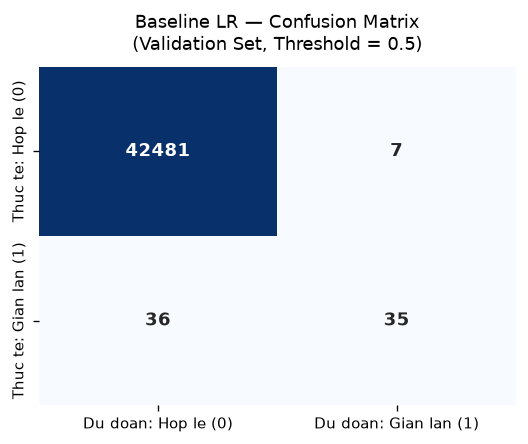

In [7]:
# 3.2 Ve Confusion Matrix cho Baseline
cm_base = confusion_matrix(y_val, base_preds, labels=[0, 1])
fig, ax = plt.subplots(figsize=(4.5, 3.8))
sns.heatmap(
    cm_base, annot=True, fmt='d', cmap='Blues', cbar=False,
    xticklabels=['Du doan: Hop le (0)', 'Du doan: Gian lan (1)'],
    yticklabels=['Thuc te: Hop le (0)', 'Thuc te: Gian lan (1)'],
    annot_kws={'size': 11, 'weight': 'bold'}, ax=ax
)
ax.set_title('Baseline LR — Confusion Matrix\n(Validation Set, Threshold = 0.5)', fontsize=11, pad=10)
plt.tight_layout()
fig.savefig(FIGURES_EXP_DIR / 'fig_baseline_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

### Nhận Xét Kết Quả Baseline:
1. **Recall rất khiêm tốn:** Ở ngưỡng mặc định 0.5 không có kỹ thuật hỗ trợ, mô hình bỏ sót một lượng lớn các giao dịch gian lận (FN cao).
2. **Precision tương đối cao:** Khi mô hình đã đưa ra cảnh báo ở ngưỡng 0.5, khả năng chính xác khá tốt, nhưng cái giá phải trả là bỏ lọt nhiều vụ gian lận.
3. **Sự cần thiết của xử lý mất cân bằng:** Để phục vụ bài toán nghiệp vụ gian lận thẻ, ta bắt buộc phải nâng cao độ nhạy (Recall / F2-score). Đây chính là động lực để thực hiện RQ1.

---
## Phần 4 — RQ1: So Sánh Các Chiến Lược Xử Lý Mất Cân Bằng Lớp

**Research Question 1:** *Which class imbalance handling technique is most effective for credit card fraud detection?*

### 4.1 Thiết Kế Thí Nghiệm Nghiêm Ngặt:
- Để đảm bảo tính khách quan và cô lập biến số nghiên cứu, ta **cố định thuật toán phân loại là Logistic Regression** trên cùng một tập phân chia.
- So sánh 4 chiến lược kinh điển:
  1. **No Resampling:** Không can thiệp vào phân phối mẫu, trọng số đều.
  2. **Random Under-Sampling (RUS):** Giảm số lượng mẫu đa số trong tập huấn luyện về bằng số mẫu gian lận.
  3. **SMOTE (Synthetic Minority Over-sampling Technique):** Sinh mẫu tổng hợp cho lớp gian lận trong không gian đặc trưng giữa các lân cận $k$-NN trên tập huấn luyện.
  4. **Class Weighting:** Điều chỉnh hàm mất mát thông qua trọng số nghịch đảo tần suất lớp (`class_weight='balanced'`) mà không làm thay đổi số lượng mẫu.
- **Quy tắc ngăn ngừa rò rỉ:** `StandardScaler` và `SMOTE` / `RUS` đều được đóng gói trong `imblearn.pipeline.Pipeline`, chỉ học trên `X_train`, áp dụng chuyển đổi khi `fit`, tuyệt đối không can thiệp vào `X_val` hay `X_test`.
- **Quy tắc tuyển chọn chiến lược tốt nhất (Selection Rule):** Lựa chọn phương pháp đạt **Validation F2-score cao nhất tại ngưỡng 0.5** (kết hợp xem xét AP và số lượng FN/FP).

In [8]:
# 4.2 Thuc hien thi nghiem RQ1 tren tap Validation
print('=== RQ1: So sanh 4 chien luoc xu ly mat can bang lop ===\n')

rq1_configs = {
    'No Resampling': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_SEED, solver='lbfgs'))
    ]),
    'Random Under-Sampling': ImbPipeline([
        ('scaler', StandardScaler()),
        ('rus', RandomUnderSampler(random_state=RANDOM_SEED)),
        ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_SEED, solver='lbfgs'))
    ]),
    'SMOTE': ImbPipeline([
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=RANDOM_SEED)),
        ('clf', LogisticRegression(max_iter=1000, random_state=RANDOM_SEED, solver='lbfgs'))
    ]),
    'Class Weighting': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_SEED, solver='lbfgs'))
    ]),
}

rq1_results = []
rq1_fitted_models = {}

for method_name, pipe in rq1_configs.items():
    print(f'Dang huan luyen: {method_name}...')
    t0 = time.time()
    pipe.fit(X_train, y_train)
    train_sec = time.time() - t0

    preds, probs = get_predictions_at_threshold(pipe, X_val, threshold=0.5)
    metrics = evaluate_binary_predictions(y_val, preds, probs, threshold=0.5)
    metrics['Method'] = method_name
    metrics['Train Time (s)'] = round(train_sec, 3)

    rq1_results.append(metrics)
    rq1_fitted_models[method_name] = pipe
    print(f"  -> F2 = {metrics['F2-score']:.4f} | AP = {metrics['Average Precision']:.4f} | Recall = {metrics['Recall']:.4f} | Prec = {metrics['Precision']:.4f} | FN = {metrics['FN']} | Time = {train_sec:.2f}s")

rq1_df = pd.DataFrame(rq1_results)
# Sap xep thu tu cot theo chuan nghien cuu
cols_order = ['Method', 'Precision', 'Recall', 'F1-score', 'F2-score', 'Average Precision', 'FP', 'FN', 'Train Time (s)']
rq1_df = rq1_df[cols_order]

# Luu ket qua RQ1 ra file
rq1_df.to_csv(TABLES_DIR / 'rq1_comparison.csv', index=False)
print('\n✔ Bang ket qua RQ1 da duoc luu vao results/tables/rq1_comparison.csv')

=== RQ1: So sanh 4 chien luoc xu ly mat can bang lop ===

Dang huan luyen: No Resampling...
  -> F2 = 0.5368 | AP = 0.6877 | Recall = 0.4930 | Prec = 0.8333 | FN = 36 | Time = 0.38s
Dang huan luyen: Random Under-Sampling...
  -> F2 = 0.1423 | AP = 0.4990 | Recall = 0.8873 | Prec = 0.0326 | FN = 8 | Time = 0.14s
Dang huan luyen: SMOTE...
  -> F2 = 0.1997 | AP = 0.6987 | Recall = 0.8873 | Prec = 0.0487 | FN = 8 | Time = 1.57s
Dang huan luyen: Class Weighting...
  -> F2 = 0.2063 | AP = 0.6971 | Recall = 0.8873 | Prec = 0.0507 | FN = 8 | Time = 0.67s

✔ Bang ket qua RQ1 da duoc luu vao results/tables/rq1_comparison.csv


In [9]:
# 4.3 Xuat Bang Paper Table 2 va xac dinh phuong phap chien thang RQ1
# Bang 2 theo tieu chuan bai bao
table2_paper = rq1_df[['Method', 'Precision', 'Recall', 'F2-score', 'Average Precision']].copy()
table2_paper.columns = ['Method', 'Precision', 'Recall', 'F2-score', 'AP']

# Luu Table 2
table2_paper.to_csv(TABLES_PAPER_DIR / 'table2_imbalance_comparison.csv', index=False)
print('=== Paper Table 2: Comparison of Class Imbalance Handling Methods ===')
print(table2_paper.to_string(index=False))

# Xac dinh chien luoc chien thang theo F2-score cao nhat tren validation
best_rq1_idx = rq1_df['F2-score'].idxmax()
SELECTED_RQ1_METHOD = rq1_df.loc[best_rq1_idx, 'Method']
SELECTED_RQ1_F2     = rq1_df.loc[best_rq1_idx, 'F2-score']
SELECTED_RQ1_AP     = rq1_df.loc[best_rq1_idx, 'Average Precision']

print(f'\n★ KET QUA TUYEN CHON RQ1: Phuong phap duoc chon la "{SELECTED_RQ1_METHOD}"')
print(f'  - Validation F2-score: {SELECTED_RQ1_F2:.4f}')
print(f'  - Validation AP:       {SELECTED_RQ1_AP:.4f}')

=== Paper Table 2: Comparison of Class Imbalance Handling Methods ===
               Method  Precision   Recall  F2-score       AP
        No Resampling   0.833333 0.492958  0.536810 0.687661
Random Under-Sampling   0.032642 0.887324  0.142276 0.498968
                SMOTE   0.048724 0.887324  0.199746 0.698725
      Class Weighting   0.050684 0.887324  0.206287 0.697147

★ KET QUA TUYEN CHON RQ1: Phuong phap duoc chon la "No Resampling"
  - Validation F2-score: 0.5368
  - Validation AP:       0.6877


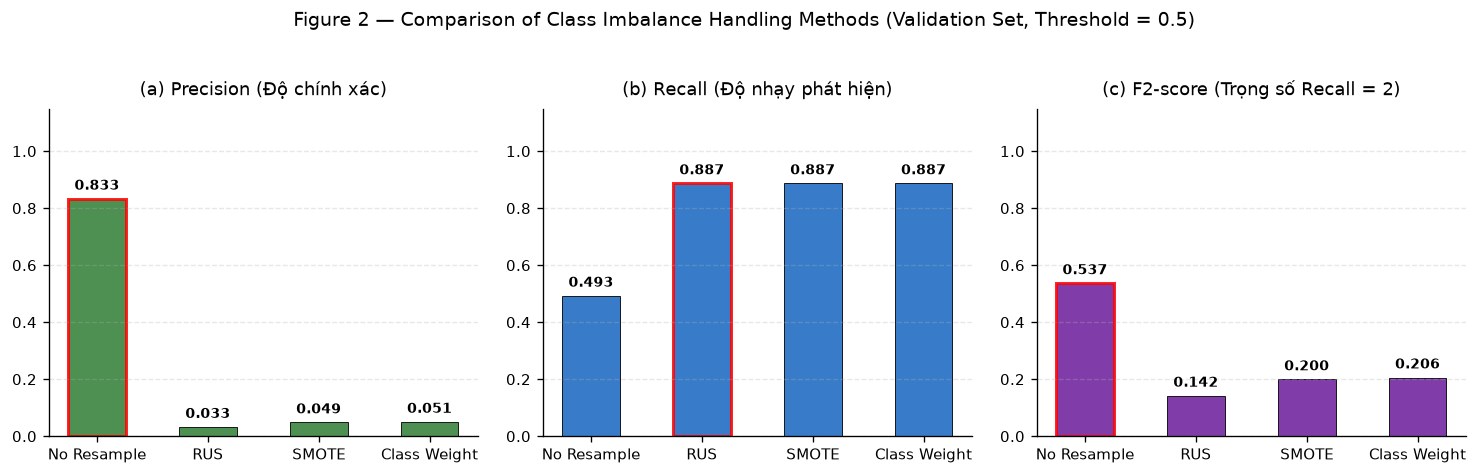

✔ Da xuat Figure 2 (PNG va PDF) vao results/figures/paper/


In [10]:
# 4.4 Ve Figure 2: So sanh 4 chien luoc xu ly mat can bang lop (Paper Figure)
methods = rq1_df['Method'].tolist()
x = np.arange(len(methods))

fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.8), sharey=False)

plot_specs = [
    ('Precision', '(a) Precision (Độ chính xác)', '#2E7D32'),
    ('Recall', '(b) Recall (Độ nhạy phát hiện)', '#1565C0'),
    ('F2-score', '(c) F2-score (Trọng số Recall = 2)', '#6A1B9A'),
]

short_names = ['No Resample', 'RUS', 'SMOTE', 'Class Weight']

for ax, (metric, title, col) in zip(axes, plot_specs):
    vals = rq1_df[metric].values
    bars = ax.bar(x, vals, color=col, width=0.52, alpha=0.85, edgecolor='black', linewidth=0.6)
    
    # Danh dau cot cao nhat
    best_i = np.argmax(vals)
    bars[best_i].set_edgecolor('red')
    bars[best_i].set_linewidth(1.8)
    
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
                f'{val:.3f}', ha='center', va='bottom', fontsize=8.5, fontweight='bold')
    
    ax.set_title(title, fontsize=10.5, pad=8)
    ax.set_xticks(x)
    ax.set_xticklabels(short_names, fontsize=9)
    ax.set_ylim(0, max(1.15, max(vals) * 1.25))
    ax.grid(axis='y', alpha=0.3, linestyle='--')

plt.suptitle('Figure 2 — Comparison of Class Imbalance Handling Methods (Validation Set, Threshold = 0.5)', fontsize=11.5, y=1.03)
plt.tight_layout()

# Luu o ca hai dinh dang PNG va PDF theo tieu chuan xuat ban
fig.savefig(FIGURES_PAPER_DIR / 'fig2_imbalance_comparison.png', dpi=300, bbox_inches='tight')
fig.savefig(FIGURES_PAPER_DIR / 'fig2_imbalance_comparison.pdf', bbox_inches='tight')
fig.savefig(FIGURES_EXP_DIR / 'fig2_imbalance_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('✔ Da xuat Figure 2 (PNG va PDF) vao results/figures/paper/')

### Diễn giải kết quả RQ1

Bảng dưới đây lấy từ tập Validation, ngưỡng 0.5, với Logistic Regression cố định cho cả bốn chiến lược.

Về Recall, No Resampling đạt 0.4930 (bắt 35 trong 71 ca gian lận, bỏ sót 36), thấp nhất trong bốn phương pháp. Random Under-Sampling, SMOTE và Class Weighting cùng đạt 0.8873 (bắt 63 ca, bỏ sót 8).

Ba phương pháp tái cân bằng phải đánh đổi bằng số báo động giả lớn ở ngưỡng 0.5: khoảng 1,180 FP với Class Weighting, 1,230 với SMOTE và 1,867 với Random Under-Sampling, trong khi No Resampling chỉ có 7 FP. Precision của ba phương pháp này nằm trong khoảng 0.033 đến 0.051 và F2-score trong khoảng 0.142 đến 0.206. Một cách giải thích khả dĩ là huấn luyện trên tỉ lệ lớp gần 1:1 làm xác suất dự đoán dịch lên cao, nên ngưỡng 0.5 không còn phù hợp. Notebook chưa kiểm tra giả thuyết này vì không quét ngưỡng riêng cho Logistic Regression ở RQ1.

No Resampling có Precision cao nhất (0.8333) và F2-score cao nhất (0.5368), nên theo quy tắc đã đặt trước (F2-score cao nhất tại ngưỡng 0.5) phương pháp này được chuyển sang RQ2. Lựa chọn này đến từ Precision và F2-score, không phải từ Recall: về Recall, No Resampling thấp hơn cả ba phương pháp còn lại.

Về Average Precision, SMOTE (0.6987), Class Weighting (0.6971) và No Resampling (0.6877) chênh nhau tối đa khoảng 0.011. Với 71 ca gian lận trên Validation và một lần chia dữ liệu, chênh lệch này chưa đủ để xếp hạng ba phương pháp. Random Under-Sampling thấp hơn rõ (0.4990).

Kết luận RQ1 chỉ áp dụng cho Logistic Regression, ngưỡng 0.5 và một lần chia dữ liệu này.


---
## Phần 5 — RQ2: So Sánh Các Mô Hình Học Máy

**Research Question 2 (Giai đoạn 1):** *Which machine learning model provides the best trade-off between fraud detection and false positive reduction?*

### 5.1 Giao Thức Tuyển Chọn Mô Hình:
1. Sáu mô hình ứng viên được huấn luyện trên cùng tập train, đánh giá trên cùng tập validation, và dùng cùng một chiến lược xử lý mất cân bằng (chiến lược đã chọn ở RQ1). Notebook không chạy lại bốn chiến lược RQ1 cho từng mô hình, để số thí nghiệm không nhân lên và kết quả dễ diễn giải.
   - Logistic Regression: mô hình tuyến tính, dùng làm mốc so sánh.
   - Random Forest: tổ hợp cây theo kiểu bagging.
   - HistGradientBoostingClassifier: boosting theo histogram của scikit-learn.
   - Linear SVM (`LinearSVC`): siêu phẳng phân cách tuyến tính, chọn thay cho SVM kernel RBF để tránh chi phí huấn luyện lớn trên dữ liệu này.
   - XGBoost: boosting của thư viện `xgboost`.
   - Balanced Random Forest (`imblearn.ensemble`): Random Forest trong đó mỗi cây học trên một mẫu đã cân bằng bằng cách lấy mẫu giảm lớp đa số. Đây là cách xử lý mất cân bằng nằm trong thuật toán, nên khác với các mô hình còn lại (không tái lấy mẫu ở bước dữ liệu), và cần nêu khi báo cáo. Để tránh cân bằng hai lần, Balanced Random Forest luôn đi qua pipeline chỉ gồm `StandardScaler` và mô hình, không áp dụng thêm SMOTE hay Random Under-Sampling bên ngoài, bất kể RQ1 chọn chiến lược nào. Vì vậy ở bảng RQ2 mô hình này mang chiến lược xử lý mất cân bằng riêng (cột `Imbalance Handling`), và kết quả của nó không so sánh trực tiếp theo cùng điều kiện với các mô hình còn lại. Vì mỗi cây thấy dữ liệu cân bằng, xác suất đầu ra có thể bị dịch lên cao, nên kết quả ở ngưỡng mặc định 0.5 chưa phản ánh hiệu năng sau khi tối ưu ngưỡng.
2. Không tinh chỉnh siêu tham số. Mỗi mô hình dùng một cấu hình cố định, ghi trong code. Nếu RQ1 chọn Class Weighting, trọng số lớp được truyền cho từng mô hình theo cách của nó (`class_weight='balanced'` cho các mô hình scikit-learn, `scale_pos_weight` cho XGBoost; Balanced Random Forest không dùng thêm trọng số). Đó là khác biệt về cách triển khai, cần nêu khi báo cáo.
3. Pipeline giữ `StandardScaler` cho cả sáu mô hình để mọi mô hình đi qua cùng đường tiền xử lý. Mô hình cây không cần bước này nhưng không bị ảnh hưởng.
4. Đánh giá ban đầu dùng ngưỡng mặc định: 0.5 cho mô hình có xác suất, 0 cho Linear SVM (biên quyết định của SVM). Điểm của Linear SVM lấy từ `decision_function`, không phải xác suất, nên không so sánh trực tiếp giá trị ngưỡng của SVM với ngưỡng của các mô hình khác.
5. Tiêu chí chọn mô hình: Validation Average Precision (AP) cao nhất. AP không phụ thuộc ngưỡng và tính được với cả điểm `decision_function`. Tiêu chí này được đặt trước khi thêm hai mô hình mới và không đổi. Lựa chọn dựa hoàn toàn trên Validation, không dùng Test. Nếu hai mô hình có AP chênh nhau rất ít, báo cáo không được viết rằng mô hình được chọn vượt trội rõ rệt.
6. XGBoost có điều kiện về thư viện: nếu thiếu hoặc huấn luyện lỗi, notebook ghi lỗi, chạy các mô hình còn lại và không điền số liệu thay thế.

7. LightGBM đã được thử ở cấu hình mặc định nhưng cho kết quả suy biến trên Validation (AP = 0.0017, xấp xỉ tỉ lệ gian lận; TP = 0), nên được loại khỏi danh sách ứng viên. Notebook không điều chỉnh siêu tham số để cứu mô hình này.

In [11]:
# 5.2 Xay dung va huan luyen cac mo hinh ung vien (toi da 6 mo hinh; XGBoost co dieu kien)
print(f'=== RQ2: So sanh mo hinh hoc may voi chien luoc: {SELECTED_RQ1_METHOD} ===\n')

# Ham tao pipeline dong nhat theo chien luoc RQ1
# Cac mo hinh tu can bang du lieu ben trong thuat toan: khong ap dung them SMOTE/RUS ben ngoai
SELF_BALANCING_MODELS = {'Balanced Random Forest'}

def create_model_pipeline(model_instance, strategy_name, seed=RANDOM_SEED, self_balancing=False):
    if self_balancing:
        # Tranh can bang hai lan: chi scaler + mo hinh, bat ke chien luoc RQ1
        return Pipeline([('scaler', StandardScaler()), ('clf', model_instance)])
    if strategy_name == 'No Resampling':
        return Pipeline([('scaler', StandardScaler()), ('clf', model_instance)])
    elif strategy_name == 'Random Under-Sampling':
        return ImbPipeline([('scaler', StandardScaler()), ('rus', RandomUnderSampler(random_state=seed)), ('clf', model_instance)])
    elif strategy_name == 'SMOTE':
        # Neu mo hinh la Tree-based, SMOTE co the ap dung truc tiep bang ImbPipeline
        return ImbPipeline([('scaler', StandardScaler()), ('smote', SMOTE(random_state=seed)), ('clf', model_instance)])
    elif strategy_name == 'Class Weighting':
        # Voi class weighting, truyen class_weight='balanced' vao mo hinh neu duoc ho tro
        return Pipeline([('scaler', StandardScaler()), ('clf', model_instance)])
    else:
        raise ValueError(f'Chien luoc khong hop le: {strategy_name}')

# Khoi tao cac mo hinh ung vien voi cau hinh co dinh (khong tinh chinh sieu tham so)
use_cw = SELECTED_RQ1_METHOD == 'Class Weighting'
cw_arg = 'balanced' if use_cw else None
n_neg_train = int((y_train == 0).sum())
n_pos_train = int((y_train == 1).sum())

candidate_models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000, class_weight=cw_arg, random_state=RANDOM_SEED, solver='lbfgs'
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=100, max_depth=15, class_weight=cw_arg, random_state=RANDOM_SEED, n_jobs=-1
    ),
    'HistGradientBoosting': HistGradientBoostingClassifier(
        max_iter=150, class_weight=cw_arg, random_state=RANDOM_SEED
    ),
    'Linear SVM': LinearSVC(
        C=1.0, dual=False, class_weight=cw_arg, max_iter=10000, random_state=RANDOM_SEED
    ),
}

rq2_failed = {}   # ten mo hinh -> ly do khong chay duoc
if XGBOOST_AVAILABLE:
    candidate_models['XGBoost'] = XGBClassifier(
        n_estimators=150, max_depth=6, learning_rate=0.1, tree_method='hist',
        eval_metric='aucpr', n_jobs=-1, random_state=RANDOM_SEED,
        scale_pos_weight=(n_neg_train / n_pos_train) if use_cw else 1.0,
    )
else:
    rq2_failed['XGBoost'] = 'thu vien xgboost chua cai dat'
    print('! Bo qua XGBoost: thu vien xgboost chua cai dat (pip install xgboost).')

# Balanced Random Forest: moi cay hoc tren mau da can bang (lay mau giam lop da so) ngay trong thuat toan.
# Dat ro cac tham so de ket qua khong phu thuoc gia tri mac dinh cua tung phien ban imbalanced-learn.
candidate_models['Balanced Random Forest'] = BalancedRandomForestClassifier(
    n_estimators=100, max_depth=15, sampling_strategy='all', replacement=True, bootstrap=False,
    random_state=RANDOM_SEED, n_jobs=-1,
)

rq2_results = []
rq2_fitted_pipelines = {}

for name, clf_inst in candidate_models.items():
    print(f'Huan luyen {name}...')
    try:
        is_self_bal = name in SELF_BALANCING_MODELS
        pipe = create_model_pipeline(clf_inst, SELECTED_RQ1_METHOD, seed=RANDOM_SEED, self_balancing=is_self_bal)
        t0 = time.time()
        pipe.fit(X_train, y_train)
        t_dur = time.time() - t0

        is_prob = has_probability_output(pipe)
        default_thr = 0.5 if is_prob else 0.0
        preds, scores = get_predictions_at_threshold(pipe, X_val, threshold=default_thr)
        m = evaluate_binary_predictions(y_val, preds, scores, threshold=default_thr)
        m['Model'] = name
        m['Imbalance Handling'] = 'Internal (balanced bootstrap per tree)' if is_self_bal else SELECTED_RQ1_METHOD
        m['Score Type'] = 'probability' if is_prob else 'decision score'
        m['Train Time (s)'] = round(t_dur, 3)
    except Exception as e:
        rq2_failed[name] = f'{type(e).__name__}: {e}'
        print(f'  ! {name} loi, bo qua: {rq2_failed[name]}')
        continue

    rq2_results.append(m)
    rq2_fitted_pipelines[name] = pipe
    print(f"  -> AP = {m['Average Precision']:.4f} | F2 = {m['F2-score']:.4f} | Recall = {m['Recall']:.4f} | Prec = {m['Precision']:.4f} | Thr = {default_thr} | Time = {t_dur:.2f}s")

if not rq2_results:
    raise RuntimeError(f'Khong mo hinh nao chay duoc: {rq2_failed}')
if rq2_failed:
    print('\nMo hinh khong chay duoc:', rq2_failed)

rq2_df = pd.DataFrame(rq2_results)
rq2_cols = ['Model', 'Imbalance Handling', 'Score Type', 'Threshold', 'Precision', 'Recall', 'F1-score', 'F2-score', 'Average Precision', 'FP', 'FN', 'Train Time (s)']
rq2_df = rq2_df[rq2_cols]

rq2_df.to_csv(TABLES_DIR / 'rq2_model_comparison.csv', index=False)
print('\n✔ Ket qua so sanh mo hinh da duoc luu vao results/tables/rq2_model_comparison.csv')


=== RQ2: So sanh mo hinh hoc may voi chien luoc: No Resampling ===

Huan luyen Logistic Regression...
  -> AP = 0.6877 | F2 = 0.5368 | Recall = 0.4930 | Prec = 0.8333 | Thr = 0.5 | Time = 0.36s
Huan luyen Random Forest...
  -> AP = 0.8267 | F2 = 0.8065 | Recall = 0.7746 | Prec = 0.9649 | Thr = 0.5 | Time = 10.43s
Huan luyen HistGradientBoosting...
  -> AP = 0.5019 | F2 = 0.5934 | Recall = 0.6620 | Prec = 0.4196 | Thr = 0.5 | Time = 0.59s
Huan luyen Linear SVM...
  -> AP = 0.7323 | F2 = 0.5124 | Recall = 0.4648 | Prec = 0.8684 | Thr = 0.0 | Time = 0.69s
Huan luyen XGBoost...
  -> AP = 0.8271 | F2 = 0.7229 | Recall = 0.6761 | Prec = 1.0000 | Thr = 0.5 | Time = 1.48s
Huan luyen Balanced Random Forest...
  -> AP = 0.7280 | F2 = 0.3551 | Recall = 0.8732 | Prec = 0.1053 | Thr = 0.5 | Time = 2.41s

✔ Ket qua so sanh mo hinh da duoc luu vao results/tables/rq2_model_comparison.csv


In [12]:
# 5.3 Xuat bang so sanh va tuyen chon mo hinh chien thang
print('=== RQ2 Model Comparison Table (nguong mac dinh: 0.5 voi xac suat, 0 voi decision score) ===')
print('Luu y: nguong cua Linear SVM (decision score) khong cung thang do voi nguong xac suat cua cac mo hinh khac; chi so sanh xep hang bang Average Precision.')
print('Luu y: Balanced Random Forest dung co che can bang rieng, khong qua SMOTE/RUS ben ngoai.\n')
print(rq2_df[['Model', 'Imbalance Handling', 'Score Type', 'Threshold', 'Precision', 'Recall', 'F2-score', 'Average Precision', 'FP', 'FN', 'Train Time (s)']].to_string(index=False))

# Tuyen chon mo hinh theo tieu chi Validation Average Precision (AP) cao nhat
best_model_idx = rq2_df['Average Precision'].idxmax()
SELECTED_MODEL_NAME = rq2_df.loc[best_model_idx, 'Model']
SELECTED_MODEL_AP   = rq2_df.loc[best_model_idx, 'Average Precision']
SELECTED_PIPELINE   = rq2_fitted_pipelines[SELECTED_MODEL_NAME]
SELECTED_IS_PROBABILITY = has_probability_output(SELECTED_PIPELINE)

print(f'\n★ MO HINH DUOC CHON (theo Validation AP cao nhat): "{SELECTED_MODEL_NAME}"')
print(f'  - Validation Average Precision: {SELECTED_MODEL_AP:.4f}')
print(f"  - Loai diem du doan: {'xac suat' if SELECTED_IS_PROBABILITY else 'decision_function (khong phai xac suat)'}")

# Ghi chu do chenh lech giua hai mo hinh dan dau (lua chon chi dua tren Validation, khong dung Test)
_top2 = rq2_df.sort_values('Average Precision', ascending=False).head(2)
if len(_top2) == 2:
    _gap2 = float(_top2.iloc[0]['Average Precision'] - _top2.iloc[1]['Average Precision'])
    print(f"  - Mo hinh xep thu hai: {_top2.iloc[1]['Model']} (AP = {_top2.iloc[1]['Average Precision']:.4f}), chenh {_gap2:.4f}")
    if _gap2 < 0.01:
        print('  ! Chenh lech AP qua nho: khong ket luan mo hinh duoc chon vuot troi ro ret; day la lua chon theo quy tac da dat truoc tren Validation.')


=== RQ2 Model Comparison Table (nguong mac dinh: 0.5 voi xac suat, 0 voi decision score) ===
Luu y: nguong cua Linear SVM (decision score) khong cung thang do voi nguong xac suat cua cac mo hinh khac; chi so sanh xep hang bang Average Precision.
Luu y: Balanced Random Forest dung co che can bang rieng, khong qua SMOTE/RUS ben ngoai.

                 Model                     Imbalance Handling     Score Type  Threshold  Precision   Recall  F2-score  Average Precision  FP  FN  Train Time (s)
   Logistic Regression                          No Resampling    probability        0.5   0.833333 0.492958  0.536810           0.687661   7  36           0.363
         Random Forest                          No Resampling    probability        0.5   0.964912 0.774648  0.806452           0.826740   2  16          10.432
  HistGradientBoosting                          No Resampling    probability        0.5   0.419643 0.661972  0.593434           0.501926  65  24           0.586
            Linear S

---
## Phần 6 — RQ2: Tối Ưu Hóa Ngưỡng Phân Loại (Threshold Optimization)

**Mục tiêu:** Tìm ngưỡng phân loại tối ưu $\theta^*$ cho **mô hình duy nhất đã được chọn** ở Phần 5, hoàn toàn dựa trên xác suất dự đoán của tập Validation.

### 6.1 Chính Sách Tuyển Chọn Ngưỡng (Policy A — Nghiên Cứu Tiên Quyết):
- Ta quét một lưới 99 ngưỡng cách đều từ $0.01$ đến $0.99$.
- **Policy A:** Lựa chọn ngưỡng $\theta^*$ tối đa hóa chỉ số **Validation F2-score**. Ngưỡng này ưu tiên Recall (trọng số gấp đôi Precision) và vẫn tính đến số giao dịch bị báo nhầm.
- **Lưu ý khi diễn giải:** F2 coi Recall quan trọng gấp đôi Precision, nên ngưỡng có F2 cao nhất chưa chắc là ngưỡng có ít False Positive nhất. Ngưỡng thấp hơn thường thu hồi thêm ca gian lận nhưng làm tăng số báo nhầm.
- **Cam kết:** Việc tối ưu ngưỡng thực hiện 100% trên tập Validation. Tuyệt đối không dùng tập Test.
- Nếu mô hình được chọn là Linear SVM, điểm dự đoán là `decision_function` nên lưới ngưỡng gồm 99 giá trị cách đều giữa điểm nhỏ nhất và lớn nhất trên Validation, không phải từ 0.01 đến 0.99.


In [13]:
# 6.2 Quet luoi nguong phan loai tren Validation set
print(f'=== Toi uu hoa nguong phan loai cho: {SELECTED_MODEL_NAME} ===')

# Lay xac suat du doan tren tap Validation
val_probs = get_scores(SELECTED_PIPELINE, X_val)   # xac suat, hoac decision_function neu la Linear SVM

if SELECTED_IS_PROBABILITY:
    threshold_grid = np.linspace(0.01, 0.99, 99)
else:
    threshold_grid = np.linspace(val_probs.min(), val_probs.max(), 99)
threshold_eval_records = []

for th in threshold_grid:
    preds_th = (val_probs >= th).astype(int)
    m = evaluate_binary_predictions(y_val, preds_th, val_probs, threshold=th)
    threshold_eval_records.append(m)

threshold_df = pd.DataFrame(threshold_eval_records)
threshold_df.to_csv(TABLES_DIR / 'rq2_threshold_results.csv', index=False)
print('✔ Da luu ket qua quet luoi nguong vao results/tables/rq2_threshold_results.csv')

# Ap dung Policy A: Chon nguong dat F2-score cao nhat tren validation
opt_idx = threshold_df['F2-score'].idxmax()
SELECTED_THRESHOLD = float(threshold_df.loc[opt_idx, 'Threshold'])
OPT_VAL_METRICS    = threshold_df.loc[opt_idx].to_dict()

print(f'\n★ NGUONG TOI UU DUOC CHON (Policy A - Max Validation F2):')
print(f"  - Nguong toi uu (theta*): {SELECTED_THRESHOLD:.3f}")
print(f"  - Validation F2-score:   {OPT_VAL_METRICS['F2-score']:.4f}")
print(f"  - Validation Recall:     {OPT_VAL_METRICS['Recall']:.4f}")
print(f"  - Validation Precision:  {OPT_VAL_METRICS['Precision']:.4f}")
print(f"  - Validation F1-score:   {OPT_VAL_METRICS['F1-score']:.4f}")
print(f"  - So luong FN (bo sot):  {int(OPT_VAL_METRICS['FN'])}")
print(f"  - So luong FP (bao nham):{int(OPT_VAL_METRICS['FP'])}")

=== Toi uu hoa nguong phan loai cho: XGBoost ===
✔ Da luu ket qua quet luoi nguong vao results/tables/rq2_threshold_results.csv

★ NGUONG TOI UU DUOC CHON (Policy A - Max Validation F2):
  - Nguong toi uu (theta*): 0.040
  - Validation F2-score:   0.8092
  - Validation Recall:     0.7887
  - Validation Precision:  0.9032
  - Validation F1-score:   0.8421
  - So luong FN (bo sot):  15
  - So luong FP (bao nham):6


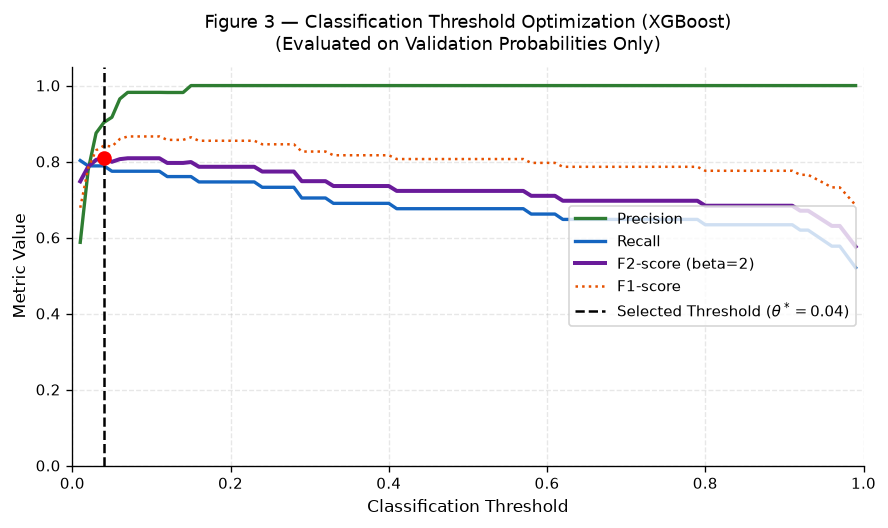

✔ Da xuat Figure 3 (PNG va PDF) vao results/figures/paper/


In [14]:
# 6.3 Ve Figure 3: Duong cong toi uu hoa nguong phan loai (Paper Figure)
fig, ax = plt.subplots(figsize=(7.5, 4.5))

th_vals = threshold_df['Threshold'].values
ax.plot(th_vals, threshold_df['Precision'].values, label='Precision', color='#2E7D32', linewidth=2.0)
ax.plot(th_vals, threshold_df['Recall'].values, label='Recall', color='#1565C0', linewidth=2.0)
ax.plot(th_vals, threshold_df['F2-score'].values, label='F2-score (beta=2)', color='#6A1B9A', linewidth=2.4)
ax.plot(th_vals, threshold_df['F1-score'].values, label='F1-score', color='#E65100', linewidth=1.5, linestyle=':')

# Duong thang dung danh dau nguong chon
ax.axvline(
    SELECTED_THRESHOLD, color='black', linestyle='--', linewidth=1.5,
    label=rf'Selected Threshold ($\theta^* = {SELECTED_THRESHOLD:.2f}$)'
)

# Danh dau diem cuc dai F2
ax.scatter([SELECTED_THRESHOLD], [OPT_VAL_METRICS['F2-score']], color='red', s=60, zorder=5)

ax.set_title(f'Figure 3 — Classification Threshold Optimization ({SELECTED_MODEL_NAME})\n(Evaluated on Validation Probabilities Only)', fontsize=11, pad=10)
ax.set_xlabel('Classification Threshold' if SELECTED_IS_PROBABILITY else 'Decision-score Threshold (not a probability)', fontsize=10)
ax.set_ylabel('Metric Value', fontsize=10)
ax.set_xlim((0, 1) if SELECTED_IS_PROBABILITY else (th_vals.min(), th_vals.max()))
ax.set_ylim(0, 1.05)
ax.grid(alpha=0.3, linestyle='--')
ax.legend(loc='center right', frameon=True, fontsize=9)

plt.tight_layout()
fig.savefig(FIGURES_PAPER_DIR / 'fig3_threshold_optimization.png', dpi=300, bbox_inches='tight')
fig.savefig(FIGURES_PAPER_DIR / 'fig3_threshold_optimization.pdf', bbox_inches='tight')
fig.savefig(FIGURES_EXP_DIR / 'fig3_threshold_optimization.png', dpi=150, bbox_inches='tight')
plt.show()
print('✔ Da xuat Figure 3 (PNG va PDF) vao results/figures/paper/')


In [15]:
# 6.4 Nhan xet ve su danh doi Precision/Recall: tao tu bang quet nguong, khong viet cung so lieu
from IPython.display import display, Markdown

_t = threshold_df.sort_values('Threshold').reset_index(drop=True)
_lo, _hi = _t.iloc[0], _t.iloc[-1]
_rmax = _t.loc[_t['Recall'].idxmax()]
_f2max = _t['F2-score'].max()
_near = _t[_t['F2-score'] >= _f2max - 0.01]
_rec_note = (f"Recall cao nhất trên toàn lưới là {_rmax['Recall']:.4f} (tại ngưỡng {_rmax['Threshold']:.2f}), "
             f"nên vẫn còn {int(_rmax['FN'])} ca gian lận bị bỏ sót ngay cả ở ngưỡng đó."
             if _rmax['Recall'] < 1 else
             f"Recall đạt {_rmax['Recall']:.4f} tại ngưỡng {_rmax['Threshold']:.2f}.")
_f2_note = (f"Có {len(_near)} ngưỡng trong lưới cho F2-score cách cực đại không quá 0.01 (từ {_near['Threshold'].min():.2f} đến {_near['Threshold'].max():.2f}), "
            "nên θ* chỉ hơn các ngưỡng lân cận một chút về F2-score trên Validation."
            if len(_near) > 1 else "Chỉ một ngưỡng trong lưới đạt F2-score gần cực đại.")

display(Markdown(f"""### Nhận xét về sự đánh đổi giữa Precision và Recall khi tối ưu ngưỡng

Số liệu lấy từ bảng quét ngưỡng trên Validation của mô hình {SELECTED_MODEL_NAME}.

1. Ở ngưỡng thấp nhất của lưới ({_lo['Threshold']:.2f}), Recall là {_lo['Recall']:.4f} và Precision là {_lo['Precision']:.4f}, với {int(_lo['FP'])} FP. {_rec_note}
2. Ở ngưỡng cao nhất của lưới ({_hi['Threshold']:.2f}), Precision là {_hi['Precision']:.4f} và Recall là {_hi['Recall']:.4f}, với {int(_hi['FN'])} FN.
3. Tại θ* = {SELECTED_THRESHOLD:.2f} (Policy A): Precision {OPT_VAL_METRICS['Precision']:.4f}, Recall {OPT_VAL_METRICS['Recall']:.4f}, F2-score {OPT_VAL_METRICS['F2-score']:.4f}, {int(OPT_VAL_METRICS['FP'])} FP và {int(OPT_VAL_METRICS['FN'])} FN.
4. {_f2_note}
"""))


### Nhận xét về sự đánh đổi giữa Precision và Recall khi tối ưu ngưỡng

Số liệu lấy từ bảng quét ngưỡng trên Validation của mô hình XGBoost.

1. Ở ngưỡng thấp nhất của lưới (0.01), Recall là 0.8028 và Precision là 0.5876, với 40 FP. Recall cao nhất trên toàn lưới là 0.8028 (tại ngưỡng 0.01), nên vẫn còn 14 ca gian lận bị bỏ sót ngay cả ở ngưỡng đó.
2. Ở ngưỡng cao nhất của lưới (0.99), Precision là 1.0000 và Recall là 0.5211, với 34 FN.
3. Tại θ* = 0.04 (Policy A): Precision 0.9032, Recall 0.7887, F2-score 0.8092, 6 FP và 15 FN.
4. Có 9 ngưỡng trong lưới cho F2-score cách cực đại không quá 0.01 (từ 0.03 đến 0.11), nên θ* chỉ hơn các ngưỡng lân cận một chút về F2-score trên Validation.


---
## Phần 7 — Đóng Băng Cấu Hình Cuối Cùng (Freeze Configuration)

**Nguyên tắc phương pháp luận:**
Trước khi chạm vào tập Test, toàn bộ cấu hình thực nghiệm phải được **đóng băng vĩnh viễn** và lưu trữ dưới dạng tệp máy tính có thể đọc (`results/final_configuration.json`).
Sau bước này, ta không được phép quay lại sửa đổi mô hình, thay đổi siêu tham số hay dịch chuyển ngưỡng bất kể kết quả trên tập Test ra sao.

In [16]:
# 7.1 Ghi nhan va dong bang cau hinh cuoi cung
import datetime

final_frozen_configuration = {
    'timestamp_frozen_utc': datetime.datetime.now(datetime.timezone.utc).isoformat(),
    'research_title': 'Credit Card Fraud Detection Using Machine Learning and Generalization Evaluation on Unseen Data',
    'random_seed': RANDOM_SEED,
    'selected_imbalance_strategy': SELECTED_RQ1_METHOD,
    'selected_model_architecture': SELECTED_MODEL_NAME,
    'model_selection_criterion': 'Highest Validation Average Precision (AP) among RQ2 candidates (threshold-independent)',
    'selected_model_imbalance_handling': ('Internal (balanced bootstrap per tree)' if SELECTED_MODEL_NAME in SELF_BALANCING_MODELS else SELECTED_RQ1_METHOD),
    'selected_model_score_type': 'probability' if SELECTED_IS_PROBABILITY else 'decision_function (not a probability)',
    'rq2_models_trained': rq2_df['Model'].tolist(),
    'rq2_models_failed': rq2_failed,
    'library_versions': LIB_VERSIONS,
    'threshold_selection_policy': 'Policy A: Maximizing Validation F2-score',
    'optimized_classification_threshold': round(SELECTED_THRESHOLD, 4),
    'optimized_classification_threshold_exact': float(SELECTED_THRESHOLD),
    'threshold_scale': 'probability' if SELECTED_IS_PROBABILITY else 'decision_function score (not comparable with probability thresholds)',
    'validation_performance_at_optimized_threshold': {
        'Precision': round(OPT_VAL_METRICS['Precision'], 4),
        'Recall': round(OPT_VAL_METRICS['Recall'], 4),
        'F1-score': round(OPT_VAL_METRICS['F1-score'], 4),
        'F2-score': round(OPT_VAL_METRICS['F2-score'], 4),
        'Average Precision': round(OPT_VAL_METRICS['Average Precision'], 4),
        'FP': int(OPT_VAL_METRICS['FP']),
        'FN': int(OPT_VAL_METRICS['FN']),
    },
}

config_save_path = RESULTS_DIR / 'final_configuration.json'
with open(config_save_path, 'w', encoding='utf-8') as f:
    json.dump(final_frozen_configuration, f, indent=2, ensure_ascii=False)

print('========================================================================')
print('★ CAU HINH CUOI CUNG DA DUOC DONG BANG HOAN TOAN VA LUU TRU THANH CONG')
print('========================================================================')
print(json.dumps(final_frozen_configuration, indent=2, ensure_ascii=False))
print(f'\n✔ File cau hinh: {config_save_path}')
print('\n-> SAN SANG CHO PHAN 8: DANH GIA TREN TAP TEST CHUA TUNG THAY (UNSEEN TEST SET)')

★ CAU HINH CUOI CUNG DA DUOC DONG BANG HOAN TOAN VA LUU TRU THANH CONG
{
  "timestamp_frozen_utc": "2026-10-29T09:18:15.386941+00:00",
  "research_title": "Credit Card Fraud Detection Using Machine Learning and Generalization Evaluation on Unseen Data",
  "random_seed": 42,
  "selected_imbalance_strategy": "No Resampling",
  "selected_model_architecture": "XGBoost",
  "model_selection_criterion": "Highest Validation Average Precision (AP) among RQ2 candidates (threshold-independent)",
  "selected_model_imbalance_handling": "No Resampling",
  "selected_model_score_type": "probability",
  "rq2_models_trained": [
    "Logistic Regression",
    "Random Forest",
    "HistGradientBoosting",
    "Linear SVM",
    "XGBoost",
    "Balanced Random Forest"
  ],
  "rq2_models_failed": {},
  "library_versions": {
    "python": "3.13.16",
    "pandas": "2.3.3",
    "numpy": "2.5.3",
    "scipy": "1.18.1",
    "sklearn": "1.9.1",
    "imblearn": "0.14.2",
    "matplotlib": "3.11.2",
    "seaborn": "0

---
## Phần 8 — RQ3: Đánh Giá Cuối Cùng Trên Tập Test Chưa Từng Thấy

**Research Question 3:** *How well does the selected machine learning model, with its optimized classification threshold, generalize to previously unseen transaction data?*

### 8.1 Thực Thi Đánh Giá Khách Quan:
- Đây là lần **đầu tiên và duy nhất** mô hình tiếp xúc với tập Test.
- Sử dụng chính xác mô hình đã huấn luyện `SELECTED_PIPELINE` và ngưỡng đã đóng băng $\theta^*$.
- Báo cáo đầy đủ ma trận nhầm lẫn (Confusion Matrix) và đường cong Precision–Recall trên tập Test.
- **Phạm vi kết luận:** Tập Test chưa được dùng để huấn luyện, chọn mô hình hay chọn ngưỡng, nhưng được chia ngẫu nhiên có phân tầng cùng nguồn với Train/Validation. Kết quả không chứng minh khả năng dự đoán giao dịch trong tương lai hay ở tổ chức khác.


In [17]:
# 8.2 Chay danh gia tren tap Test voi cau hinh dong bang
print(f'=== Danh gia tren tap Test (N = {len(X_test):,} giao dich) ===')
print(f'Mo hinh: {SELECTED_MODEL_NAME} | Chien luoc: {SELECTED_RQ1_METHOD} | Nguong theta* = {SELECTED_THRESHOLD:.3f}\n')

# Du doan xac suat va nhan tren tap test
test_preds, test_probs = get_predictions_at_threshold(SELECTED_PIPELINE, X_test, threshold=SELECTED_THRESHOLD)

# Tinh toan do do tren test
test_metrics = evaluate_binary_predictions(y_test, test_preds, test_probs, threshold=SELECTED_THRESHOLD)

print('Ket qua tren tap Test chua tung thay:')
for k, v in test_metrics.items():
    if isinstance(v, float):
        print(f'  - {k:<20}: {v:.4f}')
    else:
        print(f'  - {k:<20}: {v}')

# Luu ket qua Test
test_res_df = pd.DataFrame([test_metrics])
test_res_df.to_csv(TABLES_DIR / 'rq3_test_results.csv', index=False)
print('\n✔ Ket qua Test da duoc luu vao results/tables/rq3_test_results.csv')

=== Danh gia tren tap Test (N = 42,559 giao dich) ===
Mo hinh: XGBoost | Chien luoc: No Resampling | Nguong theta* = 0.040

Ket qua tren tap Test chua tung thay:
  - Threshold           : 0.0400
  - Precision           : 0.8056
  - Recall              : 0.8169
  - F1-score            : 0.8112
  - F2-score            : 0.8146
  - Average Precision   : 0.8159
  - Accuracy            : 0.9994
  - TP                  : 58
  - FP                  : 14
  - TN                  : 42474
  - FN                  : 13

✔ Ket qua Test da duoc luu vao results/tables/rq3_test_results.csv


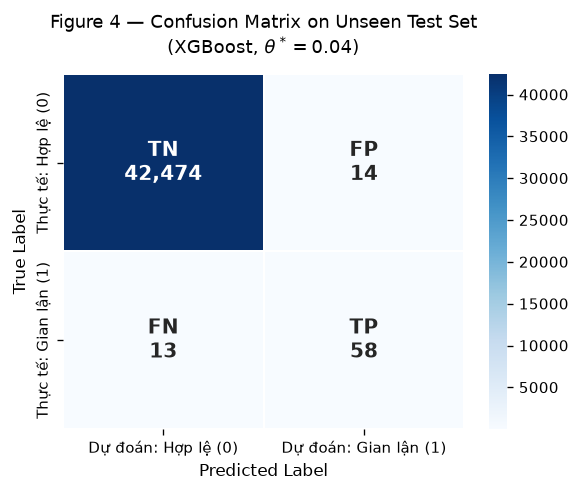

✔ Da xuat Figure 4 (PNG va PDF) vao results/figures/paper/


In [18]:
# 8.3 Ve Figure 4: Ma tran nham lan tren tap Test (Paper Figure)
cm_test = confusion_matrix(y_test, test_preds, labels=[0, 1])
tn_t, fp_t, fn_t, tp_t = cm_test.ravel()

fig, ax = plt.subplots(figsize=(5.0, 4.2))

annot_labels = np.array([
    [f'TN\n{tn_t:,}', f'FP\n{fp_t:,}'],
    [f'FN\n{fn_t:,}', f'TP\n{tp_t:,}']
])

sns.heatmap(
    cm_test, annot=annot_labels, fmt='', cmap='Blues', cbar=True,
    xticklabels=['Dự đoán: Hợp lệ (0)', 'Dự đoán: Gian lận (1)'],
    yticklabels=['Thực tế: Hợp lệ (0)', 'Thực tế: Gian lận (1)'],
    annot_kws={'size': 12, 'weight': 'bold'}, ax=ax,
    linewidths=1.0, linecolor='white'
)

ax.set_title(f'Figure 4 — Confusion Matrix on Unseen Test Set\n({SELECTED_MODEL_NAME}, $\\theta^* = {SELECTED_THRESHOLD:.2f}$)', fontsize=11, pad=12)
ax.set_xlabel('Predicted Label', fontsize=10)
ax.set_ylabel('True Label', fontsize=10)

plt.tight_layout()
fig.savefig(FIGURES_PAPER_DIR / 'fig4_test_confusion_matrix.png', dpi=300, bbox_inches='tight')
fig.savefig(FIGURES_PAPER_DIR / 'fig4_test_confusion_matrix.pdf', bbox_inches='tight')
fig.savefig(FIGURES_EXP_DIR / 'fig4_test_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print('✔ Da xuat Figure 4 (PNG va PDF) vao results/figures/paper/')


Operating point tai theta* = 0.04: Precision = 0.8056, Recall = 0.8169 (khop du doan va duong cong)


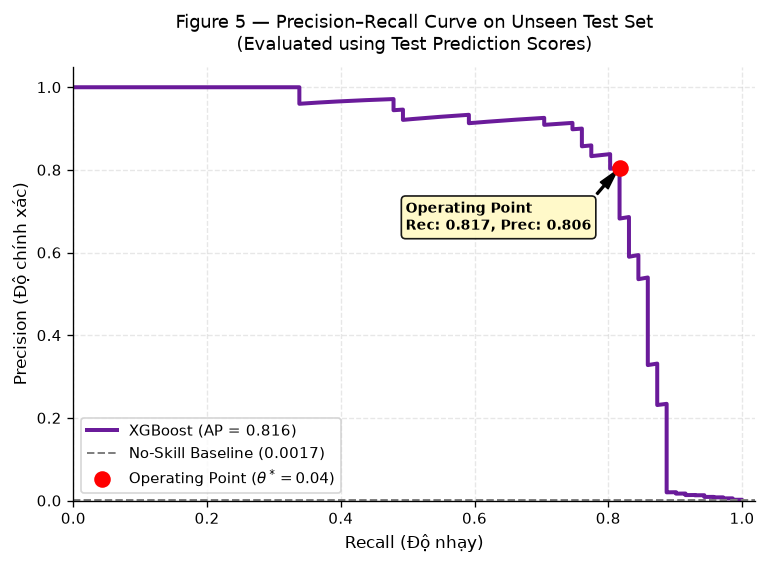

✔ Da xuat Figure 5 (PNG va PDF) vao results/figures/paper/


In [19]:
# 8.4 Ve Figure 5: Duong cong Precision-Recall tren tap Test (Paper Figure)
prec_curve, rec_curve, th_curve = precision_recall_curve(y_test, test_probs, pos_label=1)
test_ap_score = average_precision_score(y_test, test_probs, pos_label=1)
no_skill_baseline = (y_test == 1).sum() / len(y_test)

fig, ax = plt.subplots(figsize=(6.5, 4.8))

# Ve duong PR cua mo hinh
ax.plot(rec_curve, prec_curve, color='#6A1B9A', linewidth=2.4, label=f'{SELECTED_MODEL_NAME} (AP = {test_ap_score:.3f})')

# Ve duong No-Skill Baseline
ax.axhline(no_skill_baseline, color='gray', linestyle='--', linewidth=1.2, label=f'No-Skill Baseline ({no_skill_baseline:.4f})')

# Diem van hanh tai SELECTED_THRESHOLD.
# Quy uoc cua precision_recall_curve: prec_curve va rec_curve dai hon th_curve dung 1 phan tu
# (diem cuoi la Precision = 1, Recall = 0, khong co nguong). Voi i < len(th_curve),
# prec_curve[i], rec_curve[i] ung voi du doan 'score >= th_curve[i]'.
# Du doan 'score >= theta*' trung voi diem co th_curve[i] dau tien >= theta*, nen dung searchsorted.
# Gia tri van hanh lay truc tiep tu du doan tai theta*, de khop Confusion Matrix (Figure 4).
pt_prec = precision_score(y_test, test_preds, pos_label=1, zero_division=0)
pt_rec  = recall_score(y_test, test_preds, pos_label=1, zero_division=0)

curve_idx = int(np.searchsorted(th_curve, SELECTED_THRESHOLD, side='left'))
if curve_idx >= len(th_curve):
    raise ValueError('SELECTED_THRESHOLD lon hon moi nguong tren duong cong PR cua Test.')
assert np.isclose(prec_curve[curve_idx], pt_prec) and np.isclose(rec_curve[curve_idx], pt_rec), (
    f'Diem tren duong cong (P={prec_curve[curve_idx]:.4f}, R={rec_curve[curve_idx]:.4f}) '
    f'khong khop du doan tai theta* (P={pt_prec:.4f}, R={pt_rec:.4f}).'
)
assert np.isclose(pt_prec, test_metrics['Precision']) and np.isclose(pt_rec, test_metrics['Recall'])
print(f'Operating point tai theta* = {SELECTED_THRESHOLD:.2f}: Precision = {pt_prec:.4f}, Recall = {pt_rec:.4f} (khop du doan va duong cong)')

ax.scatter([pt_rec], [pt_prec], color='red', s=80, zorder=5, label=rf'Operating Point ($\theta^* = {SELECTED_THRESHOLD:.2f}$)')
ax.annotate(
    f'Operating Point\nRec: {pt_rec:.3f}, Prec: {pt_prec:.3f}',
    xy=(pt_rec, pt_prec), xytext=(pt_rec - 0.32, pt_prec - 0.15),
    arrowprops=dict(facecolor='black', shrink=0.08, width=1, headwidth=6),
    fontsize=8.5, fontweight='bold', bbox=dict(boxstyle='round,pad=0.3', facecolor='#FFF9C4', alpha=0.9)
)

ax.set_title(f'Figure 5 — Precision–Recall Curve on Unseen Test Set\n(Evaluated using Test Prediction Scores)', fontsize=11, pad=10)
ax.set_xlabel('Recall (Độ nhạy)', fontsize=10)
ax.set_ylabel('Precision (Độ chính xác)', fontsize=10)
ax.set_xlim(0, 1.02)
ax.set_ylim(0, 1.05)
ax.grid(alpha=0.3, linestyle='--')
ax.legend(loc='lower left', frameon=True, fontsize=9)

plt.tight_layout()
fig.savefig(FIGURES_PAPER_DIR / 'fig5_test_pr_curve.png', dpi=300, bbox_inches='tight')
fig.savefig(FIGURES_PAPER_DIR / 'fig5_test_pr_curve.pdf', bbox_inches='tight')
fig.savefig(FIGURES_EXP_DIR / 'fig5_test_pr_curve.png', dpi=150, bbox_inches='tight')
plt.show()
print('✔ Da xuat Figure 5 (PNG va PDF) vao results/figures/paper/')


---
## Phần 9 — Phân Tích Tổng Quát Hóa: Validation vs. Unseen Test

**Mục tiêu:** So sánh trực diện hiệu năng giữa tập Validation và tập Test khi sử dụng **cùng một cấu hình đóng băng**.

### 9.1 Đánh Giá Độ Ổn Định:
- Tính toán độ lệch tuyệt đối (Absolute Difference) và tỷ lệ biến thiên tương đối (Relative Change %).
- Thực hiện phương pháp **Non-parametric Bootstrap (1,000 lần lặp)** trên tập Test để ước lượng khoảng tin cậy 95% (95% Confidence Intervals) cho các độ đo cốt lõi (Recall và Average Precision).

In [20]:
# 9.2 Tao Paper Table 4: Final Generalization Results
gen_metrics_keys = ['Precision', 'Recall', 'F2-score', 'Average Precision', 'FP', 'FN']

table4_rows = []
for k in gen_metrics_keys:
    val_v  = OPT_VAL_METRICS[k] if k in OPT_VAL_METRICS else OPT_VAL_METRICS.get('Average Precision' if k == 'Average Precision' else k)
    test_v = test_metrics[k]
    abs_diff = abs(test_v - val_v)
    rel_chg  = ((test_v - val_v) / (val_v + 1e-9)) * 100
    
    val_str  = f'{int(val_v)}' if k in ['FP', 'FN'] else f'{val_v:.3f}'
    test_str = f'{int(test_v)}' if k in ['FP', 'FN'] else f'{test_v:.3f}'
    diff_str = f'{int(abs_diff)}' if k in ['FP', 'FN'] else f'{abs_diff:.3f}'
    
    table4_rows.append({
        'Metric': 'False Positives' if k == 'FP' else ('False Negatives' if k == 'FN' else k),
        'Validation': val_str,
        'Unseen Test': test_str,
        'Abs. Diff': diff_str,
        'Relative Change (%)': f'{rel_chg:+.2f}%'
    })

table4_df = pd.DataFrame(table4_rows)

# Luu Table 4 theo dinh dang Paper
table4_paper = table4_df[['Metric', 'Validation', 'Unseen Test']].copy()
table4_paper.to_csv(TABLES_PAPER_DIR / 'table4_generalization_results.csv', index=False)
table4_df.to_csv(TABLES_DIR / 'generalization_comparison_full.csv', index=False)

print('=== Paper Table 4: Final Generalization Results ===')
print(table4_paper.to_string(index=False))
print('\nChi tiet bien thien:')
print(table4_df[['Metric', 'Validation', 'Unseen Test', 'Abs. Diff', 'Relative Change (%)']].to_string(index=False))


=== Paper Table 4: Final Generalization Results ===
           Metric Validation Unseen Test
        Precision      0.903       0.806
           Recall      0.789       0.817
         F2-score      0.809       0.815
Average Precision      0.827       0.816
  False Positives          6          14
  False Negatives         15          13

Chi tiet bien thien:
           Metric Validation Unseen Test Abs. Diff Relative Change (%)
        Precision      0.903       0.806     0.098             -10.81%
           Recall      0.789       0.817     0.028              +3.57%
         F2-score      0.809       0.815     0.005              +0.66%
Average Precision      0.827       0.816     0.011              -1.35%
  False Positives          6          14         8            +133.33%
  False Negatives         15          13         2             -13.33%


In [21]:
# 9.3 Bootstrap Confidence Intervals tren tap Test (N=1,000)
print('=== Tinh toan 95% Bootstrap Confidence Intervals tren tap Test (1,000 iterations) ===')

np.random.seed(RANDOM_SEED)
N_BOOT = 1000
boot_recalls = []
boot_aps     = []

y_test_arr  = np.array(y_test)
test_preds_arr = np.array(test_preds)
test_probs_arr = np.array(test_probs)
n_test_len  = len(y_test_arr)

for b_i in range(N_BOOT):
    sample_indices = np.random.choice(n_test_len, size=n_test_len, replace=True)
    b_y_true = y_test_arr[sample_indices]
    b_y_pred = test_preds_arr[sample_indices]
    b_y_prob = test_probs_arr[sample_indices]

    # Chi tinh khi co it nhat 1 mau fraud trong tap bootstrap
    if b_y_true.sum() > 0:
        boot_recalls.append(recall_score(b_y_true, b_y_pred, pos_label=1, zero_division=0))
        boot_aps.append(average_precision_score(b_y_true, b_y_prob, pos_label=1))

rec_ci_lower, rec_ci_upper = np.percentile(boot_recalls, [2.5, 97.5])
ap_ci_lower,  ap_ci_upper  = np.percentile(boot_aps,     [2.5, 97.5])

bootstrap_results = {
    'Metric': ['Recall', 'Average Precision'],
    'Point Estimate': [test_metrics['Recall'], test_metrics['Average Precision']],
    '95% CI Lower': [rec_ci_lower, ap_ci_lower],
    '95% CI Upper': [rec_ci_upper, ap_ci_upper],
}
boot_df = pd.DataFrame(bootstrap_results)
boot_df.to_csv(TABLES_DIR / 'bootstrap_ci_results.csv', index=False)

print(boot_df.to_string(index=False))
n_fraud_test = int((y_test == 1).sum())
print(f'\n✔ Khoang tin cay Bootstrap giup luong hoa bien dong thong ke do kich thuoc mau fraud trong tap test nho ({n_fraud_test} mau).')


=== Tinh toan 95% Bootstrap Confidence Intervals tren tap Test (1,000 iterations) ===
           Metric  Point Estimate  95% CI Lower  95% CI Upper
           Recall        0.816901      0.727194      0.901414
Average Precision        0.815915      0.727430      0.893718

✔ Khoang tin cay Bootstrap giup luong hoa bien dong thong ke do kich thuoc mau fraud trong tap test nho (71 mau).


In [22]:
# 9.4 Nhan xet kha nang tong quat hoa: tao tu ket qua da chay, khong viet cung so lieu
from IPython.display import display, Markdown

def _dir(d, eps=0.005):
    return 'cao hơn' if d > eps else ('thấp hơn' if d < -eps else 'gần như không đổi so với')

_rows = [('Recall', 'Recall'), ('Average Precision', 'AP'), ('F2-score', 'F2-score'), ('Precision', 'Precision')]
_parts = '; '.join(
    f"{lbl} {OPT_VAL_METRICS[k]:.4f} → {test_metrics[k]:.4f} ({test_metrics[k] - OPT_VAL_METRICS[k]:+.4f})"
    for k, lbl in _rows)
_worse = [lbl for k, lbl in _rows if test_metrics[k] - OPT_VAL_METRICS[k] < -0.05]
_worse_note = (f"Chỉ số giảm rõ nhất (quá 0.05): {', '.join(_worse)}." if _worse
               else "Không chỉ số nào trong bốn chỉ số trên giảm quá 0.05.")
_fp_v, _fp_t = int(OPT_VAL_METRICS['FP']), int(test_metrics['FP'])
_fn_v, _fn_t = int(OPT_VAL_METRICS['FN']), int(test_metrics['FN'])

_top = rq2_df.sort_values('Average Precision', ascending=False).head(2)
n_val_fraud  = manifest['class_counts']['validation']['fraud']
n_test_fraud = manifest['class_counts']['test']['fraud']
if len(_top) == 2:
    _gap = float(_top.iloc[0]['Average Precision'] - _top.iloc[1]['Average Precision'])
    _sel_note = (f" {_top.iloc[0]['Model']} được chọn vì có AP Validation cao nhất ({_top.iloc[0]['Average Precision']:.4f}); "
                 f"mô hình đứng thứ hai là {_top.iloc[1]['Model']} ({_top.iloc[1]['Average Precision']:.4f}), chênh {_gap:.4f}."
                 + (f" Với {n_val_fraud} ca gian lận trên Validation, chênh lệch này quá nhỏ để coi hai mô hình khác nhau về khả năng xếp hạng, và thứ tự có thể đổi nếu chia dữ liệu khác." if _gap < 0.01 else ""))
else:
    _sel_note = ""

_rec_in = rec_ci_lower <= OPT_VAL_METRICS['Recall'] <= rec_ci_upper
_ap_in  = ap_ci_lower <= OPT_VAL_METRICS['Average Precision'] <= ap_ci_upper
_ci_note = ("Giá trị Validation của cả hai chỉ số nằm trong khoảng tin cậy này, nên với cỡ mẫu hiện tại chưa tách được chênh lệch quan sát với dao động ngẫu nhiên."
            if (_rec_in and _ap_in) else
            "Có ít nhất một giá trị Validation nằm ngoài khoảng tin cậy tương ứng trên Test, nên chênh lệch ở chỉ số đó đáng chú ý hơn dao động ngẫu nhiên do cỡ mẫu.")

display(Markdown(f"""### Nhận xét khả năng tổng quát hóa

1. Từ Validation sang Test: {_parts}. FP {_fp_v} → {_fp_t}, FN {_fn_v} → {_fn_t}. Recall trên Test {_dir(test_metrics['Recall'] - OPT_VAL_METRICS['Recall'])} Validation, AP {_dir(test_metrics['Average Precision'] - OPT_VAL_METRICS['Average Precision'])} Validation, Precision {_dir(test_metrics['Precision'] - OPT_VAL_METRICS['Precision'])} Validation. {_worse_note}

2. Mô hình ({SELECTED_MODEL_NAME}) được chọn theo AP trên Validation và ngưỡng θ* = {SELECTED_THRESHOLD:.2f} được chọn bằng cách tối đa hóa F2-score cũng trên Validation. Vì cả hai bước dùng Validation, số liệu Validation có thể hơi lạc quan.{_sel_note}

3. Tập Test có {n_test_fraud} ca gian lận, nên một ca chuyển từ TP sang FN làm Recall đổi khoảng {100 / n_test_fraud:.1f}%. Khoảng tin cậy Bootstrap 95% trên Test là {rec_ci_lower:.3f} đến {rec_ci_upper:.3f} cho Recall và {ap_ci_lower:.3f} đến {ap_ci_upper:.3f} cho Average Precision. {_ci_note} Bootstrap ở đây chỉ lấy lại mẫu các dự đoán trên Test, không huấn luyện lại mô hình và không lặp lại bước chọn mô hình hay chọn ngưỡng.

4. Từ các số liệu trên, chưa thể kết luận mô hình có hay không có overfitting, cũng như chưa thể nói mức tổng quát hóa là cao hay thấp. Có thể mô tả từng chỉ số như ở mục 1 và theo dõi thêm các chỉ số giảm rõ nhất.

5. Test được tách bằng chia ngẫu nhiên có phân tầng, nên kết quả chỉ nói về các giao dịch cùng phân phối thời gian và cùng nguồn ngân hàng với dữ liệu huấn luyện. Chưa có bằng chứng về tổng quát hóa theo thời gian hay sang ngân hàng khác.
"""))


### Nhận xét khả năng tổng quát hóa

1. Từ Validation sang Test: Recall 0.7887 → 0.8169 (+0.0282); AP 0.8271 → 0.8159 (-0.0112); F2-score 0.8092 → 0.8146 (+0.0054); Precision 0.9032 → 0.8056 (-0.0977). FP 6 → 14, FN 15 → 13. Recall trên Test cao hơn Validation, AP thấp hơn Validation, Precision thấp hơn Validation. Chỉ số giảm rõ nhất (quá 0.05): Precision.

2. Mô hình (XGBoost) được chọn theo AP trên Validation và ngưỡng θ* = 0.04 được chọn bằng cách tối đa hóa F2-score cũng trên Validation. Vì cả hai bước dùng Validation, số liệu Validation có thể hơi lạc quan. XGBoost được chọn vì có AP Validation cao nhất (0.8271); mô hình đứng thứ hai là Random Forest (0.8267), chênh 0.0004. Với 71 ca gian lận trên Validation, chênh lệch này quá nhỏ để coi hai mô hình khác nhau về khả năng xếp hạng, và thứ tự có thể đổi nếu chia dữ liệu khác.

3. Tập Test có 71 ca gian lận, nên một ca chuyển từ TP sang FN làm Recall đổi khoảng 1.4%. Khoảng tin cậy Bootstrap 95% trên Test là 0.727 đến 0.901 cho Recall và 0.727 đến 0.894 cho Average Precision. Giá trị Validation của cả hai chỉ số nằm trong khoảng tin cậy này, nên với cỡ mẫu hiện tại chưa tách được chênh lệch quan sát với dao động ngẫu nhiên. Bootstrap ở đây chỉ lấy lại mẫu các dự đoán trên Test, không huấn luyện lại mô hình và không lặp lại bước chọn mô hình hay chọn ngưỡng.

4. Từ các số liệu trên, chưa thể kết luận mô hình có hay không có overfitting, cũng như chưa thể nói mức tổng quát hóa là cao hay thấp. Có thể mô tả từng chỉ số như ở mục 1 và theo dõi thêm các chỉ số giảm rõ nhất.

5. Test được tách bằng chia ngẫu nhiên có phân tầng, nên kết quả chỉ nói về các giao dịch cùng phân phối thời gian và cùng nguồn ngân hàng với dữ liệu huấn luyện. Chưa có bằng chứng về tổng quát hóa theo thời gian hay sang ngân hàng khác.


---
## Phần 10 — Phân Tích Lỗi Thực Nghiệm (Error Analysis)

**Mục tiêu:** Mổ xẻ các trường hợp mô hình phân loại sai trên tập Test (chỉ phục vụ mục đích hiểu biết sau thực nghiệm, không dùng để sửa đổi mô hình).

- **False Positives (FP):** Giao dịch hợp lệ nhưng bị mô hình nghi ngờ là gian lận.
- **False Negatives (FN):** Giao dịch gian lận thực tế nhưng bị mô hình bỏ lọt.

> **Lưu ý:** Các đặc trưng $V_1 - V_{28}$ là kết quả ẩn danh hóa qua PCA, ta tập trung phân tích vào các đặc trưng quan sát được trong thực tế là `Amount` (số tiền) và `Time` (thời điểm giao dịch).

In [23]:
# 10.1 Trich xuat cac tap con loi FP va FN tren Test set
test_analysis_df = X_test.copy()
test_analysis_df['True_Class']      = y_test.values
test_analysis_df['Predicted_Class'] = test_preds
test_analysis_df['Predicted_Prob']  = test_probs

# Gan nhan nhom ket qua
def classify_outcome(row):
    if row['True_Class'] == 1 and row['Predicted_Class'] == 1: return 'TP'
    if row['True_Class'] == 0 and row['Predicted_Class'] == 0: return 'TN'
    if row['True_Class'] == 0 and row['Predicted_Class'] == 1: return 'FP'
    if row['True_Class'] == 1 and row['Predicted_Class'] == 0: return 'FN'
    return 'Unknown'

test_analysis_df['Outcome'] = test_analysis_df.apply(classify_outcome, axis=1)

fp_subset = test_analysis_df[test_analysis_df['Outcome'] == 'FP']
fn_subset = test_analysis_df[test_analysis_df['Outcome'] == 'FN']
tp_subset = test_analysis_df[test_analysis_df['Outcome'] == 'TP']

print(f'Thong ke so luong tren Test set:')
print(f"  - True Positives (TP):  {len(tp_subset)} giao dich fraud bat dung")
print(f"  - False Positives (FP): {len(fp_subset)} giao dich hop le bi bao nham")
print(f"  - False Negatives (FN): {len(fn_subset)} giao dich fraud bi bo sot")

error_stats = test_analysis_df.groupby('Outcome')[['Amount', 'Time', 'Predicted_Prob']].agg(['count', 'mean', 'median', 'std']).round(2)
print('\nBang thong ke dac trung theo nhom ket qua:')
display(error_stats)

Thong ke so luong tren Test set:
  - True Positives (TP):  58 giao dich fraud bat dung
  - False Positives (FP): 14 giao dich hop le bi bao nham
  - False Negatives (FN): 13 giao dich fraud bi bo sot

Bang thong ke dac trung theo nhom ket qua:


Amount                          Time                               \
         count    mean median     std  count      mean   median       std   
Outcome                                                                     
FN          13  248.23  29.95  357.76     13  94748.46  75556.0  39704.45   
FP          14   59.26   1.26  122.06     14  94742.50  96879.0  58978.68   
TN       42474   89.72  22.26  247.79  42474  94468.82  84255.0  47422.79   
TP          58  103.68  11.50  190.38     58  79688.71  80878.0  46469.85   

        Predicted_Prob                     
                 count  mean median   std  
Outcome                                    
FN                  13  0.00   0.00  0.01  
FP                  14  0.40   0.18  0.41  
TN               42474  0.00   0.00  0.00  
TP                  58  0.88   1.00  0.27

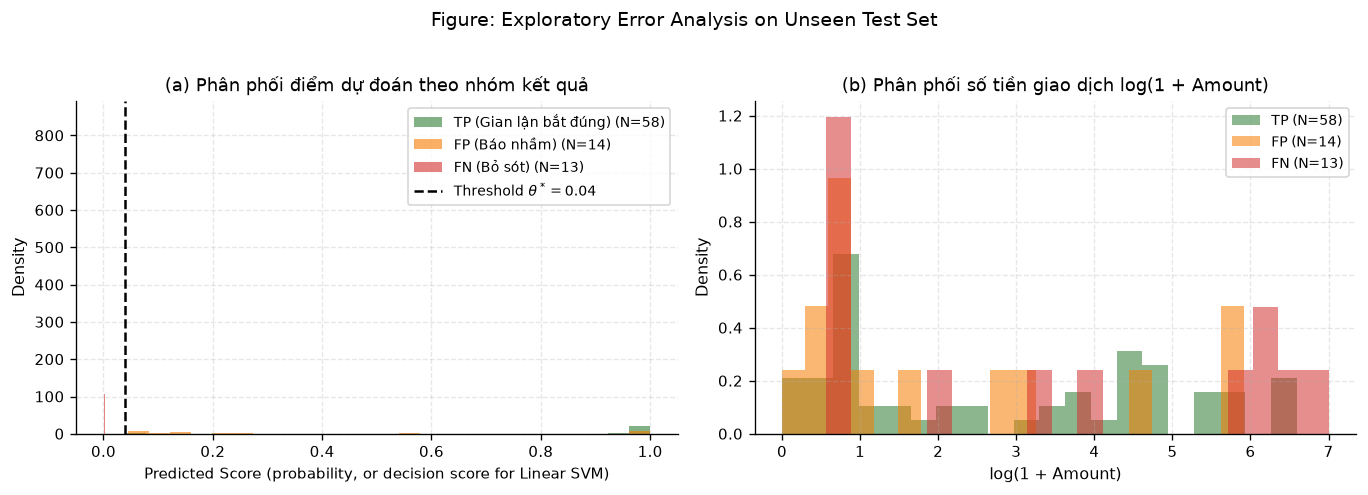

✔ Da luu bieu do phan tich loi vao results/figures/exploratory/


In [24]:
# 10.2 Ve bieu do phan tich dac trung Amount va Predicted Prob cua cac truong hop loi
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.0))

# Subplot 1: Phan phoi xac suat du doan
for outcome, col, lbl in [('TP', '#2E7D32', 'TP (Gian lận bắt đúng)'),
                          ('FP', '#F57C00', 'FP (Báo nhầm)'),
                          ('FN', '#D32F2F', 'FN (Bỏ sót)')]:
    sub_p = test_analysis_df[test_analysis_df['Outcome'] == outcome]['Predicted_Prob']
    if len(sub_p) > 0:
        axes[0].hist(sub_p, bins=25, alpha=0.6, label=f'{lbl} (N={len(sub_p)})', color=col, density=True)

axes[0].axvline(SELECTED_THRESHOLD, color='black', linestyle='--', linewidth=1.5, label=f'Threshold $\\theta^* = {SELECTED_THRESHOLD:.2f}$') 
axes[0].set_title('(a) Phân phối điểm dự đoán theo nhóm kết quả', fontsize=10.5)
axes[0].set_xlabel('Predicted Score (probability, or decision score for Linear SVM)', fontsize=9)
axes[0].set_ylabel('Density', fontsize=9.5)
axes[0].legend(fontsize=8.5)
axes[0].grid(alpha=0.3, linestyle='--')

# Subplot 2: Phan phoi so tien giao dich Amount (log scale)
for outcome, col, lbl in [('TP', '#2E7D32', 'TP'),
                          ('FP', '#F57C00', 'FP'),
                          ('FN', '#D32F2F', 'FN')]:
    sub_a = test_analysis_df[test_analysis_df['Outcome'] == outcome]['Amount']
    if len(sub_a) > 0:
        axes[1].hist(np.log1p(sub_a), bins=20, alpha=0.55, label=f'{lbl} (N={len(sub_a)})', color=col, density=True)

axes[1].set_title('(b) Phân phối số tiền giao dịch log(1 + Amount)', fontsize=10.5)
axes[1].set_xlabel('log(1 + Amount)', fontsize=9.5)
axes[1].set_ylabel('Density', fontsize=9.5)
axes[1].legend(fontsize=8.5)
axes[1].grid(alpha=0.3, linestyle='--')

plt.suptitle('Figure: Exploratory Error Analysis on Unseen Test Set', fontsize=11.5, y=1.02)
plt.tight_layout()
fig.savefig(FIGURES_EXP_DIR / 'fig_error_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print('✔ Da luu bieu do phan tich loi vao results/figures/exploratory/')


In [25]:
# 10.3 Nhan xet phan tich loi: tao tu test_analysis_df, khong viet cung so lieu
from IPython.display import display, Markdown

_df = test_analysis_df
def _col(o, c): return _df.loc[_df['Outcome'] == o, c]
_n = {o: int((_df['Outcome'] == o).sum()) for o in ['TP', 'FP', 'FN', 'TN']}
_th = SELECTED_THRESHOLD

_fn_p = _col('FN', 'Predicted_Prob')
# Voi xac suat: mot nua theta*. Voi decision score (Linear SVM) theta* co the am nen 'mot nua' vo nghia:
# dung diem giua trung vi TN va theta*.
_fn_cut = _th / 2 if SELECTED_IS_PROBABILITY else (float(_col('TN', 'Predicted_Prob').median()) + _th) / 2
_fn_low = int((_fn_p < _fn_cut).sum())
_fn_note = ("Như vậy phần lớn FN không nằm sát dưới ngưỡng: mô hình gán cho chúng điểm gần như điểm của giao dịch hợp lệ "
            f"(trung vị TN là {_col('TN', 'Predicted_Prob').median():.3f}), nên hạ ngưỡng ở mức vừa phải khó thu hồi các ca này."
            if _n['FN'] and _fn_low >= _n['FN'] / 2 else
            "Một phần đáng kể FN nằm khá gần ngưỡng, nên hạ ngưỡng có thể thu hồi thêm một số ca và đổi lại FP tăng. Notebook không thử vì θ* đã đóng băng.")

_fp_p = _col('FP', 'Predicted_Prob')
_fp_hi_note = (f" Có {int((_fp_p >= 0.5).sum())}/{_n['FP']} ca có điểm từ 0.5 trở lên." if SELECTED_IS_PROBABILITY else "")
_fp_a = _col('FP', 'Amount')
_fp_skew = (" Trung bình lớn hơn nhiều trung vị, nên một vài giao dịch có số tiền lớn kéo trung bình lên; bảng chưa cho biết có bao nhiêu ca như vậy."
            if _fp_a.median() > 0 and _fp_a.mean() > 3 * _fp_a.median() else "")
_fp_vs_tn = 'thấp hơn' if _fp_a.median() < _col('TN', 'Amount').median() else 'cao hơn'

display(Markdown(f"""### Nhận xét phân tích lỗi

Phần này mô tả các nhóm kết quả trên tập Test ({SELECTED_MODEL_NAME}, θ* = {_th:.2f}) bằng các thống kê ở trên. Nhóm FN có {_n['FN']} ca và nhóm FP có {_n['FP']} ca, nên các nhận xét mang tính mô tả, chưa kiểm định thống kê.

1. FN (gian lận bị bỏ sót). Điểm dự đoán có trung bình {_fn_p.mean():.3f}, trung vị {_fn_p.median():.3f}, độ lệch chuẩn {_fn_p.std():.3f}. Có {_fn_low}/{_n['FN']} ca có điểm dưới {'một nửa θ*' if SELECTED_IS_PROBABILITY else 'điểm giữa trung vị TN và θ*'} ({_fn_cut:.3f}). {_fn_note}

2. Số tiền của FN có trung vị {_col('FN', 'Amount').median():.2f}, trung bình {_col('FN', 'Amount').mean():.2f}, độ lệch chuẩn {_col('FN', 'Amount').std():.2f}. Trung vị của TP là {_col('TP', 'Amount').median():.2f} và của TN là {_col('TN', 'Amount').median():.2f}. Với {_n['FN']} ca, chưa đủ cơ sở để kết luận gian lận bị bỏ sót có mẫu số tiền riêng.

3. FP (giao dịch hợp lệ bị báo nhầm). Điểm dự đoán có trung bình {_fp_p.mean():.3f}, trung vị {_fp_p.median():.3f}, độ lệch chuẩn {_fp_p.std():.3f}.{_fp_hi_note} Số tiền của FP có trung vị {_fp_a.median():.2f}, trung bình {_fp_a.mean():.2f}, độ lệch chuẩn {_fp_a.std():.2f}; trung vị này {_fp_vs_tn} trung vị của TN ({_col('TN', 'Amount').median():.2f}).{_fp_skew} Notebook chưa phân tích nguyên nhân của các ca FP.

4. `Time` là số giây tương đối kể từ giao dịch đầu tiên, không phải giờ trong ngày. Trung vị của `Time` là {_col('FN', 'Time').median():,.0f} ở FN, {_col('FP', 'Time').median():,.0f} ở FP, {_col('TN', 'Time').median():,.0f} ở TN và {_col('TP', 'Time').median():,.0f} ở TP. Với số ca nhỏ ở FN và FP và chưa có kiểm định, không rút ra được mẫu thời gian nào, và không thể nói lỗi xảy ra ở khung giờ nào của ngày.

5. Các thành phần PCA V1 đến V28 chưa được phân tích riêng cho từng nhóm lỗi, nên chưa có cơ sở nói đặc trưng nào gây ra lỗi.
"""))


### Nhận xét phân tích lỗi

Phần này mô tả các nhóm kết quả trên tập Test (XGBoost, θ* = 0.04) bằng các thống kê ở trên. Nhóm FN có 13 ca và nhóm FP có 14 ca, nên các nhận xét mang tính mô tả, chưa kiểm định thống kê.

1. FN (gian lận bị bỏ sót). Điểm dự đoán có trung bình 0.003, trung vị 0.000, độ lệch chuẩn 0.005. Có 13/13 ca có điểm dưới một nửa θ* (0.020). Như vậy phần lớn FN không nằm sát dưới ngưỡng: mô hình gán cho chúng điểm gần như điểm của giao dịch hợp lệ (trung vị TN là 0.000), nên hạ ngưỡng ở mức vừa phải khó thu hồi các ca này.

2. Số tiền của FN có trung vị 29.95, trung bình 248.23, độ lệch chuẩn 357.76. Trung vị của TP là 11.50 và của TN là 22.26. Với 13 ca, chưa đủ cơ sở để kết luận gian lận bị bỏ sót có mẫu số tiền riêng.

3. FP (giao dịch hợp lệ bị báo nhầm). Điểm dự đoán có trung bình 0.399, trung vị 0.178, độ lệch chuẩn 0.408. Có 5/14 ca có điểm từ 0.5 trở lên. Số tiền của FP có trung vị 1.26, trung bình 59.26, độ lệch chuẩn 122.06; trung vị này thấp hơn trung vị của TN (22.26). Trung bình lớn hơn nhiều trung vị, nên một vài giao dịch có số tiền lớn kéo trung bình lên; bảng chưa cho biết có bao nhiêu ca như vậy. Notebook chưa phân tích nguyên nhân của các ca FP.

4. `Time` là số giây tương đối kể từ giao dịch đầu tiên, không phải giờ trong ngày. Trung vị của `Time` là 75,556 ở FN, 96,879 ở FP, 84,255 ở TN và 80,878 ở TP. Với số ca nhỏ ở FN và FP và chưa có kiểm định, không rút ra được mẫu thời gian nào, và không thể nói lỗi xảy ra ở khung giờ nào của ngày.

5. Các thành phần PCA V1 đến V28 chưa được phân tích riêng cho từng nhóm lỗi, nên chưa có cơ sở nói đặc trưng nào gây ra lỗi.


---
## Phần 11 — Kết Quả Nghiên Cứu Cuối Cùng và Báo Cáo Xuất Bản

Phần này tổng hợp lời giải chính thức cho ba câu hỏi nghiên cứu, xuất các bảng chuẩn bài báo còn lại (Table 1 và Table 3), kiểm toán ngân sách hình/bảng (Publication Budget) và lập danh mục artifacts.

In [26]:
# 11.1 Xuat Paper Table 1: Dataset Characteristics and Class Distribution
total_tx   = manifest['dataset_dimensions']['total_rows']
total_leg  = manifest['class_counts']['total']['legitimate']
total_frd  = manifest['class_counts']['total']['fraud']
fraud_rate = (total_frd / total_tx) * 100

table1_data = {
    'Characteristic': [
        'Total Transactions',
        'Legitimate Transactions (Class 0)',
        'Fraudulent Transactions (Class 1)',
        'Fraud Rate (%)',
        'Total Features (V1-V28, Time, Amount)',
        'Training Set Samples (70%)',
        'Validation Set Samples (15%)',
        'Test Set Samples (15%)',
        'Fraud Count in Train',
        'Fraud Count in Validation',
        'Fraud Count in Test',
    ],
    'Value': [
        f'{total_tx:,}',
        f'{total_leg:,}',
        f'{total_frd:,}',
        f'{fraud_rate:.4f}%',
        f"{manifest['n_features']}",
        f"{manifest['class_counts']['train']['rows']:,}",
        f"{manifest['class_counts']['validation']['rows']:,}",
        f"{manifest['class_counts']['test']['rows']:,}",
        f"{manifest['class_counts']['train']['fraud']:,}",
        f"{manifest['class_counts']['validation']['fraud']:,}",
        f"{manifest['class_counts']['test']['fraud']:,}",
    ]
}
table1_df = pd.DataFrame(table1_data)
table1_df.to_csv(TABLES_PAPER_DIR / 'table1_dataset_summary.csv', index=False)

print('=== Paper Table 1: Dataset Characteristics and Class Distribution ===')
print(table1_df.to_string(index=False))

=== Paper Table 1: Dataset Characteristics and Class Distribution ===
                       Characteristic   Value
                   Total Transactions 283,726
    Legitimate Transactions (Class 0) 283,253
    Fraudulent Transactions (Class 1)     473
                       Fraud Rate (%) 0.1667%
Total Features (V1-V28, Time, Amount)      30
           Training Set Samples (70%) 198,608
         Validation Set Samples (15%)  42,559
               Test Set Samples (15%)  42,559
                 Fraud Count in Train     331
            Fraud Count in Validation      71
                  Fraud Count in Test      71


In [27]:
# 11.2 Xuat Paper Table 3: Model Comparison and Threshold Selection
# Theo yeu cau H3: Table 3 phai phan biet ro so sanh ban dau o nguong 0.5 va diem hoat dong toi uu rieng cua mo hinh duoc chon
t3_rows = []

# Cac mo hinh o muc so sanh ban dau 0.5
for _, r in rq2_df.iterrows():
    t3_rows.append({
        'Model': r['Model'],
        'Imbalance Handling': r['Imbalance Handling'],
        'Score Type': r['Score Type'],
        'Evaluation Threshold': f"{r['Threshold']:.2f} (Default)",
        'Precision': f"{r['Precision']:.3f}",
        'Recall': f"{r['Recall']:.3f}",
        'F2-score': f"{r['F2-score']:.3f}",
        'AP': f"{r['Average Precision']:.3f}",
    })

# Them dong rieng cho mo hinh chien thang o nguong toi uu
t3_rows.append({
    'Model': f"{SELECTED_MODEL_NAME} (Optimized θ*)",
    'Imbalance Handling': ('Internal (balanced bootstrap per tree)' if SELECTED_MODEL_NAME in SELF_BALANCING_MODELS else SELECTED_RQ1_METHOD),
    'Score Type': 'probability' if SELECTED_IS_PROBABILITY else 'decision score',
    'Evaluation Threshold': f'{SELECTED_THRESHOLD:.3f} (Policy A: Max F2)',
    'Precision': f"{OPT_VAL_METRICS['Precision']:.3f}",
    'Recall': f"{OPT_VAL_METRICS['Recall']:.3f}",
    'F2-score': f"{OPT_VAL_METRICS['F2-score']:.3f}",
    'AP': f"{OPT_VAL_METRICS['Average Precision']:.3f}",
})

table3_paper = pd.DataFrame(t3_rows)
table3_paper.to_csv(TABLES_PAPER_DIR / 'table3_model_threshold_comparison.csv', index=False)

print('=== Paper Table 3: Model Comparison and Threshold Selection ===')
print(table3_paper.to_string(index=False))

=== Paper Table 3: Model Comparison and Threshold Selection ===
                 Model                     Imbalance Handling     Score Type     Evaluation Threshold Precision Recall F2-score    AP
   Logistic Regression                          No Resampling    probability           0.50 (Default)     0.833  0.493    0.537 0.688
         Random Forest                          No Resampling    probability           0.50 (Default)     0.965  0.775    0.806 0.827
  HistGradientBoosting                          No Resampling    probability           0.50 (Default)     0.420  0.662    0.593 0.502
            Linear SVM                          No Resampling decision score           0.00 (Default)     0.868  0.465    0.512 0.732
               XGBoost                          No Resampling    probability           0.50 (Default)     1.000  0.676    0.723 0.827
Balanced Random Forest Internal (balanced bootstrap per tree)    probability           0.50 (Default)     0.105  0.873    0.355 0.72

In [ ]:
# 11.3 Tong hop tra loi 3 Cau Hoi Nghien Cuu tu so lieu thuc te
print('='*80)
print('TONG HOP KET QUA KHOA HOC CUA DU AN')
print('='*80)

sel_rq1    = rq1_df.loc[best_rq1_idx]
higher_rec = rq1_df[rq1_df['Recall'] > sel_rq1['Recall']]
max_rec    = rq1_df['Recall'].max()
max_rec_names = ', '.join(rq1_df.loc[rq1_df['Recall'] == max_rec, 'Method'])

if higher_rec.empty:
    rq1_recall_line = f"Phuong phap nay cung co Recall cao nhat ({max_rec:.4f})."
else:
    rq1_recall_line = (
        f"Recall cua phuong phap nay ({sel_rq1['Recall']:.4f}) THAP HON cac phuong phap con lai co Recall cao hon "
        f"({max_rec:.4f}: {max_rec_names}). Nhung phuong phap do co FP tu {int(higher_rec['FP'].min())} den "
        f"{int(higher_rec['FP'].max())}, so voi {int(sel_rq1['FP'])} FP cua '{SELECTED_RQ1_METHOD}'."
    )

rq1_ans = f"""RQ1 — XU LY MAT CAN BANG LOP:
  Tai nguong 0.5 tren tap Validation, theo tieu chi tien quyet F2-score cao nhat:
  -> '{SELECTED_RQ1_METHOD}' (F2-score = {SELECTED_RQ1_F2:.4f}, AP = {SELECTED_RQ1_AP:.4f}, Precision = {sel_rq1['Precision']:.4f}, Recall = {sel_rq1['Recall']:.4f}).
  {rq1_recall_line}
  Phuong phap duoc chon nho Precision va F2-score, khong phai nho Recall.
  Ket luan chi ap dung cho Logistic Regression, nguong 0.5 va mot lan chia du lieu."""

rq2_fail_note = "" if not rq2_failed else " Khong chay duoc: " + "; ".join(f"{k} ({v})" for k, v in rq2_failed.items()) + "."

rq2_ans = f"""RQ2 — SO SANH MO HINH VA TOI UU NGUONG: \n  Da so sanh {len(rq2_df)} mo hinh ({', '.join(rq2_df['Model'])}). Balanced Random Forest dung co che can bang rieng; Linear SVM dung decision score, chi so sanh bang AP.{rq2_fail_note}\n  Mo hinh co Average Precision cao nhat tren tap Validation la: \n  -> '{SELECTED_MODEL_NAME}' (Average Precision = {SELECTED_MODEL_AP:.4f}).\n  Sau khi ap dung Policy A toi uu hoa nguong tren tap Validation, nguong toi uu duoc xac lap tai:\n  -> theta* = {SELECTED_THRESHOLD:.2f}.\n  Tai nguong nay, Validation F2-score dat {OPT_VAL_METRICS['F2-score']:.4f} (Recall: {OPT_VAL_METRICS['Recall']:.4f}, Precision: {OPT_VAL_METRICS['Precision']:.4f}, FN = {int(OPT_VAL_METRICS['FN'])}, FP = {int(OPT_VAL_METRICS['FP'])})."""

d_ap   = test_metrics['Average Precision'] - OPT_VAL_METRICS['Average Precision']
d_f2   = test_metrics['F2-score']          - OPT_VAL_METRICS['F2-score']
d_rec  = test_metrics['Recall']            - OPT_VAL_METRICS['Recall']
d_prec = test_metrics['Precision']         - OPT_VAL_METRICS['Precision']
def _dir(d, eps=0.005):
    return 'cao hon' if d > eps else ('thap hon' if d < -eps else 'gan nhu khong doi so voi')

rec_in_ci = rec_ci_lower <= OPT_VAL_METRICS['Recall']            <= rec_ci_upper
ap_in_ci  = ap_ci_lower  <= OPT_VAL_METRICS['Average Precision'] <= ap_ci_upper

rq3_ans = f"""RQ3 — HIEU NANG TREN DU LIEU CHUA TUNG THAY (UNSEEN TEST SET):
  Khi danh gia cau hinh dong bang tren tap Test doc lap:
  - Test Average Precision: {test_metrics['Average Precision']:.4f} (Validation: {OPT_VAL_METRICS['Average Precision']:.4f}, chenh {d_ap:+.4f})
  - Test F2-score:          {test_metrics['F2-score']:.4f} (Validation: {OPT_VAL_METRICS['F2-score']:.4f}, chenh {d_f2:+.4f})
  - Test Recall:            {test_metrics['Recall']:.4f} (Validation: {OPT_VAL_METRICS['Recall']:.4f}, chenh {d_rec:+.4f})
  - Test Precision:         {test_metrics['Precision']:.4f} (Validation: {OPT_VAL_METRICS['Precision']:.4f}, chenh {d_prec:+.4f})
  - So ca FN bo sot:        {test_metrics['FN']} / {manifest['class_counts']['test']['fraud']} ca gian lan (Validation: {int(OPT_VAL_METRICS['FN'])}).
  - So ca FP bao nham:      {test_metrics['FP']} / {manifest['class_counts']['test']['legitimate']} ca hop le (Validation: {int(OPT_VAL_METRICS['FP'])}).
  - Bootstrap 95% CI tren Test: Recall [{rec_ci_lower:.3f}, {rec_ci_upper:.3f}], AP [{ap_ci_lower:.3f}, {ap_ci_upper:.3f}].
  Dien giai than trong: Recall tren Test {_dir(d_rec)} Validation ({d_rec:+.3f}), AP {_dir(d_ap)} Validation ({d_ap:+.3f});
  gia tri Validation {'nam trong' if rec_in_ci else 'nam NGOAI'} khoang tin cay cua Recall va {'nam trong' if ap_in_ci else 'nam NGOAI'} khoang tin cay cua AP tren Test.
  Precision tren Test {_dir(d_prec)} Validation ({d_prec:+.3f}) va FP chuyen tu {int(OPT_VAL_METRICS['FP'])} len {test_metrics['FP']}.
  Test chi co {manifest['class_counts']['test']['fraud']} ca gian lan va nguong duoc chon tren Validation, nen cac chenh lech nay
  chua du de ket luan mo hinh co hay khong bi overfitting. Ket qua chi noi ve du lieu chia ngau nhien cung phan phoi,
  khong noi ve tong quat hoa theo thoi gian hay sang ngan hang khac."""

print(rq1_ans)
print('-'*80)
print(rq2_ans)
print('-'*80)
print(rq3_ans)
print('='*80)

TONG HOP KET QUA KHOA HOC CUA DU AN
RQ1 — XU LY MAT CAN BANG LOP:
  Tai nguong 0.5 tren tap Validation, theo tieu chi tien quyet F2-score cao nhat:
  -> 'No Resampling' (F2-score = 0.5368, AP = 0.6877, Precision = 0.8333, Recall = 0.4930).
  Recall cua phuong phap nay (0.4930) THAP HON cac phuong phap con lai co Recall cao hon (0.8873: Random Under-Sampling, SMOTE, Class Weighting). Nhung phuong phap do co FP tu 1180 den 1867, so voi 7 FP cua 'No Resampling'.
  Phuong phap duoc chon nho Precision va F2-score, khong phai nho Recall.
  Ket luan chi ap dung cho Logistic Regression, nguong 0.5 va mot lan chia du lieu.
--------------------------------------------------------------------------------
RQ2 — SO SANH MO HINH VA TOI UU NGUONG: 
  Da so sanh 6 mo hinh (Logistic Regression, Random Forest, HistGradientBoosting, Linear SVM, XGBoost, Balanced Random Forest). Balanced Random Forest (neu co) dung co che can bang rieng; Linear SVM (neu co) dung decision score, chi so sanh bang AP.
  Mo h

### 11.4 Hạn Chế Nghiên Cứu và Hướng Phát Triển Tương Lai

#### Hạn Chế (Research Limitations):
1. **Phân chia ngẫu nhiên (Random Holdout Split):** Đánh giá tổng quát hóa chỉ giới hạn trên các giao dịch độc lập cùng phân phối thời gian và không gian ngân hàng. Nghiên cứu chưa thiết lập tính tổng quát hóa tương lai (future-time out-of-distribution) hay chuyển giao liên ngân hàng (cross-bank generalization).
2. **Đặc trưng bị ẩn danh hóa:** Các biến $V_1 - V_{28}$ là kết quả của phép biến đổi PCA, do đó không thể giải thích cụ thể theo nghiệp vụ ngân hàng thực tế (như địa điểm quẹt thẻ, loại thẻ, danh mục người bán).
3. **Giả định hàm chi phí F2:** Việc sử dụng $F_2$ ($\beta = 2$) là một chuẩn mực nghiên cứu hợp lý, nhưng trong thực tế ngân hàng, tỷ lệ chi phí giữa tổn thất tài chính trực tiếp và chi phí vận hành xử lý khiếu nại khách hàng có thể thay đổi tùy thuộc vào quy mô từng tổ chức phát hành thẻ.

#### Hướng Nghiên Cứu Tương Lai (Future Research):
1. **Đánh giá theo trục thời gian (Chronological / Out-of-Time Validation):** Huấn luyện trên các tháng trước và kiểm thử trên các tháng tương lai để nghiên cứu hiện tượng trôi dạt khái niệm (concept drift) trong hành vi lừa đảo.
2. **Hiệu chỉnh xác suất (Probability Calibration):** Ứng dụng Isotonic Regression hoặc Platt Scaling để xác suất dự đoán phản ánh chính xác tần suất rủi ro thực tế.
3. **Học máy nhạy cảm chi phí thực nghiệm (Cost-Sensitive Learning):** Tích hợp trực tiếp ma trận ma trận tổn thất tài chính bằng tiền mặt vào hàm mục tiêu tối ưu.


In [29]:
# 11.5 Kiem ke toan bo Artifacts da tao va doi chieu ngan sach xuat ban (Publication Budget)
print('='*80)
print('KIEM TOAN NGAN SACH XUAT BAN (PUBLICATION BUDGET: <= 5 FIGURES, <= 4 TABLES)')
print('='*80)

# 1. Kiem tra Paper Figures (<= 5)
paper_figs = sorted([f for f in FIGURES_PAPER_DIR.glob('*.png')])
print(f'\n[1] So luong Paper Figures (Toi da 5 hinh): {len(paper_figs)} hinh')
for pf in paper_figs:
    print(f'  ✔ {pf.name:<32} ({pf.stat().st_size / 1024:.1f} KB)')
assert len(paper_figs) <= 5, 'Vuot qua ngan sach 5 hinh cho bai bao!'

# 2. Kiem tra Paper Tables (<= 4)
paper_tbls = sorted([f for f in TABLES_PAPER_DIR.glob('*.csv')])
print(f'\n[2] So luong Paper Tables (Toi da 4 bang): {len(paper_tbls)} bang')
for pt in paper_tbls:
    print(f'  ✔ {pt.name:<36} ({pt.stat().st_size / 1024:.1f} KB)')
assert len(paper_tbls) <= 4, 'Vuot qua ngan sach 4 bang cho bai bao!'

# 3. Kiem tra cac file phan tich bo sung
print('\n[3] Danh muc cac file so lieu, cau hinh va hinh anh bo sung:')
for f_path in sorted(RESULTS_DIR.rglob('*')):
    if f_path.is_file() and 'paper' not in str(f_path):
        rel_p = f_path.relative_to(PROJECT_ROOT)
        print(f'  - {str(rel_p):<55} ({f_path.stat().st_size / 1024:.1f} KB)')

print('\n' + '='*80)
print('✔ Notebook B hoan tat. So hinh va so bang nam trong ngan sach xuat ban.')
print('='*80)

KIEM TOAN NGAN SACH XUAT BAN (PUBLICATION BUDGET: <= 5 FIGURES, <= 4 TABLES)

[1] So luong Paper Figures (Toi da 5 hinh): 5 hinh
  ✔ fig1_class_distribution.png      (53.0 KB)
  ✔ fig2_imbalance_comparison.png    (133.0 KB)
  ✔ fig3_threshold_optimization.png  (152.7 KB)
  ✔ fig4_test_confusion_matrix.png   (91.7 KB)
  ✔ fig5_test_pr_curve.png           (136.6 KB)

[2] So luong Paper Tables (Toi da 4 bang): 4 bang
  ✔ table1_dataset_summary.csv           (0.4 KB)
  ✔ table2_imbalance_comparison.csv      (0.4 KB)
  ✔ table3_model_threshold_comparison.csv (0.7 KB)
  ✔ table4_generalization_results.csv    (0.2 KB)

[3] Danh muc cac file so lieu, cau hinh va hinh anh bo sung:
  - results\figures\exploratory\amount_distribution.png     (60.5 KB)
  - results\figures\exploratory\class_distribution.png      (36.9 KB)
  - results\figures\exploratory\correlation_analysis.png    (145.2 KB)
  - results\figures\exploratory\feature_distributions_top6.png (144.2 KB)
  - results\figures\exploratory\fi